# 🍊 전국 전체 시장(32개 공영도매시장) 감귤(하우스감귤 & 노지감귤) 가격·판매량 예측 AI (GPU 가속 & 기상 융합)

본 프로그램은 **`data\data1.csv`**, **`data\data2.csv`**(전국 32개 공영도매시장 경매 원본: 2018~2026년)와 **`data\forecast.csv`**(기상청 기상 관측 데이터: 2018~2026년) **3개 파일만을 입력으로 활용**하여, 전국 전체 시장 단위의 **총 거래물량(`volume`)**과 **가중평균 거래가격(`price`)**을 추정·예측하는 시계열 AI 시스템입니다:

1. **`data\data1.csv` & `data\data2.csv` (전국 32개 도매시장 경매 원본)**: 서울가락, 대구북부, 대전오정, 광주각화, 부산반여 등 전국 32개 공영도매시장의 9개년(2018~2026년, 106,018건) 일별 경매 원본 데이터
2. **전체 시장 단위 전처리 집계**: 일자별·품종별로 전국 도매시장 **총거래물량(kg)**을 합산(`volume`)하고, 총거래금액을 총거래물량으로 나눈 **가중평균 5kg상자 가격(`price`)** 및 **kg당 단가(`unitprice`)**를 산출
3. **`data\forecast.csv` (기상청 제주 관측 실측 데이터)**: 제주도 4대 핵심 관측소(제주, 서귀포, 성산, 고산)의 9개년(2018~2026년, 12,936행) 일별 기상 관측 데이터 (`평균기온`, `강수 계속시간`, `10분 최다 강수량`, `합계 일조시간`, `적설 여부`)

### 활용 모델 (GPU 가속 & 기상 + 노지감귤 대체재 변수 결합 하이브리드 앙상블)
1. **XGBoost (GPU, Weather + Field Tangerine + Global-Local Hybrid)** (`tree_method='hist', device='cuda', objective='reg:absoluteerror'`)
2. **LightGBM (Weather + Field Tangerine + Global-Local Hybrid & 분위수 회귀)** (`objective='regression_l1'` & `quantile`)
3. **Temporal Fusion Transformer (TFT, PyTorch CUDA + AMP)** (기상 변수 및 노지감귤 대체재 시장 지표를 인코더·디코더 입력으로 활용)
4. **Ensemble (XGBoost + LightGBM + TFT 검증 셋 최적 가중 결합)**
5. **주간 최고일(Top-2 Peak Days) 예측**: 특정 기준일로부터 향후 1주일 내 전국 최고 가격/물량 2개 날짜 예측 및 비율 기반 정확도 산출


## 0. 필수 라이브러리 설치 및 GPU 환경 설정
필요한 패키지가 설치되어 있지 않다면 아래 코드를 실행하거나 터미널에서 pip install -r requirements.txt를 실행하세요.
(NVIDIA GPU 환경인 경우 CUDA 호환 PyTorch 설치 권장)

In [ ]:
# 1) requirements.txt를 통한 의존성 일괄 설치 (필요시 주석 해제)
# !pip install -r requirements.txt

# 2) 개별 패키지 설치 가이드 (NVIDIA GPU CUDA 12.8 예시)
# !pip install torch --index-url https://download.pytorch.org/whl/cu128
# !pip install numpy pandas matplotlib seaborn scikit-learn xgboost lightgbm lightning pytorch-forecasting

In [7]:
import os
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import xgboost as xgb
import lightgbm as lgb
import torch

warnings.filterwarnings('ignore')

# 한글 폰트 및 시각화 기본 설정 (Windows Malgun Gothic 우선 적용)
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.family'] = 'Malgun Gothic' if os.name == 'nt' else 'DejaVu Sans'
plt.rcParams['axes.unicode_minus'] = False

# ==========================================
# GPU 가속 환경 감지 및 모델별 디바이스 설정
# ==========================================
USE_CUDA = torch.cuda.is_available()
device = torch.device('cuda' if USE_CUDA else 'cpu')
if USE_CUDA:
    torch.backends.cudnn.benchmark = True
    gpu_name = torch.cuda.get_device_name(0)
    vram_gb = torch.cuda.get_device_properties(0).total_memory / (1024 ** 3)
    print(f"[PyTorch GPU 활성화] 디바이스: {device} ({gpu_name}, VRAM: {vram_gb:.1f} GB, CUDA: {torch.version.cuda})")
else:
    print(f"[PyTorch 디바이스] {device} (CUDA 미감지 - GPU 사용 시 CUDA 지원 PyTorch 설치 필요)")

# XGBoost GPU 지원 여부 확인 (tree_method='hist', device='cuda')
def get_xgb_gpu_params():
    try:
        _test_m = xgb.XGBRegressor(tree_method='hist', device='cuda', n_estimators=1)
        _test_m.fit(np.zeros((4, 2)), np.zeros(4))
        print("[XGBoost GPU 활성화] tree_method='hist', device='cuda'")
        return {'tree_method': 'hist', 'device': 'cuda'}
    except Exception as e:
        print(f"[XGBoost CPU 모드] GPU 비활성 ({e})")
        return {'tree_method': 'hist', 'device': 'cpu', 'n_jobs': -1}

# LightGBM 디바이스 설정 (USE_LGB_GPU=True 설정 시 GPU 시도, 실패 시 CPU 멀티코어 자동 폴백)
def get_lgb_gpu_params(try_gpu=False):
    if try_gpu:
        for dev in ['cuda', 'gpu']:
            try:
                _test_m = lgb.LGBMRegressor(device=dev, n_estimators=1, verbose=-1)
                _test_m.fit(np.random.randn(10, 2), np.random.randn(10))
                print(f"[LightGBM GPU 활성화] device='{dev}'")
                return {'device': dev, 'n_jobs': -1}
            except Exception:
                continue
    print("[LightGBM 고속 병렬 모드] device='cpu', n_jobs=-1 (Windows 기본 패키지는 CMake GPU 빌드가 비활성화되어 있어 멀티코어 병렬 학습 적용)")
    return {'device': 'cpu', 'n_jobs': -1}

XGB_DEVICE_PARAMS = get_xgb_gpu_params()
LGB_DEVICE_PARAMS = get_lgb_gpu_params()

[PyTorch 디바이스] cpu (CUDA 미감지 - GPU 사용 시 CUDA 지원 PyTorch 설치 필요)
[XGBoost GPU 활성화] tree_method='hist', device='cuda'
[LightGBM 고속 병렬 모드] device='cpu', n_jobs=-1 (Windows 기본 패키지는 CMake GPU 빌드가 비활성화되어 있어 멀티코어 병렬 학습 적용)


## 1. `data1.csv`, `data2.csv`, `forecast.csv` 3대 원본 데이터 로드 및 전국 전체 시장 단위 전처리
- **경매 데이터 전처리 (`data1.csv` + `data2.csv`)**:
  - 전국 32개 공영도매시장의 9개년(2018-01-02 ~ 2026-11-07, 106,018건) 경매 데이터를 통합 로드합니다.
  - 일자별로 전국 모든 도매시장의 총 거래물량을 합산하여 **전국 전체물량(`volume`, kg)**을 구하고, 총 거래금액을 총 거래물량으로 나누어 5kg상자 규격에 맞춘 **전국 가중평균 가격(`price`, 원/5kg)** 및 **kg당 단가(`unitprice`)**를 산출합니다.
  - 하우스감귤 데이터를 타깃 시계열(`raw_df`)로 구축하고, 노지감귤(조생귤, 극조생감귤, 온주) 데이터를 강력한 대체재 시장 지표(`field_*`)로 분리 집계합니다.
- **기상 데이터 (`forecast.csv`) 전처리**:
  - 제주도 4개 관측소(제주, 서귀포, 성산, 고산)의 2018~2026년 일별 실측 기상 데이터를 평균 및 최대치로 집계합니다.
  - 단기(1~7일) 및 중장기(7·14·30·60일) 누적 일조시간·적산기온·강수시간 등 **47개 기상 파생 피처**를 구축하여 결측치 없이 경매 데이터와 1:1 결합합니다.


In [8]:
import re
from pathlib import Path

import numpy as np
import pandas as pd

def parse_weight_kg(kind_str):
    m = re.search(r"(\d+(?:\.\d+)?)\s*kg", str(kind_str))
    return float(m.group(1)) if m else 5.0

def load_and_preprocess_weather_data(weather_path=r"data\forecast.csv"):
    candidates = [
        Path(weather_path),
        Path("data/forecast.csv"),
        Path("../data/forecast.csv")
    ]
    target_path = next((p for p in candidates if p.exists()), None)
    if target_path is None:
        raise FileNotFoundError(f"날씨 데이터 파일을 찾을 수 없습니다: {weather_path}")
        
    print(f"기상청 날씨 데이터 로드 경로: {target_path.resolve()}")
    for enc in ['cp949', 'euc-kr', 'utf-8', 'utf-8-sig']:
        try:
            wdf = pd.read_csv(target_path, encoding=enc)
            break
        except UnicodeDecodeError:
            continue
            
    wdf.columns = [c.strip() for c in wdf.columns]
    date_col = next((c for c in wdf.columns if c in ['일시', 'date', 'DATE']), wdf.columns[0])
    wdf['date'] = pd.to_datetime(wdf[date_col], errors='coerce')
    wdf = wdf.dropna(subset=['date']).copy()
    
    temp_col = next((c for c in wdf.columns if '기온' in c), None)
    rain_dur_col = next((c for c in wdf.columns if '강수' in c and '계속' in c), None)
    rain_max_col = next((c for c in wdf.columns if '최다' in c and '강수' in c), None)
    sun_col = next((c for c in wdf.columns if '일조' in c), None)
    snow_col = next((c for c in wdf.columns if '적설' in c), None)
    
    wdf['temp'] = pd.to_numeric(wdf[temp_col], errors='coerce') if temp_col else np.nan
    wdf['rain_dur'] = pd.to_numeric(wdf[rain_dur_col], errors='coerce').fillna(0.0) if rain_dur_col else 0.0
    wdf['rain_peak'] = pd.to_numeric(wdf[rain_max_col], errors='coerce').fillna(0.0) if rain_max_col else 0.0
    wdf['sun_hr'] = pd.to_numeric(wdf[sun_col], errors='coerce') if sun_col else np.nan
    wdf['is_snow'] = (pd.to_numeric(wdf[snow_col], errors='coerce') > 0).astype(int) if snow_col else 0
    
    wx_daily = wdf.groupby('date', as_index=False).agg(
        wx_temp_mean=('temp', 'mean'),
        wx_temp_max=('temp', 'max'),
        wx_temp_min=('temp', 'min'),
        wx_rain_dur=('rain_dur', 'mean'),
        wx_rain_dur_max=('rain_dur', 'max'),
        wx_rain_peak=('rain_peak', 'max'),
        wx_sun_hr=('sun_hr', 'mean'),
        wx_is_snow=('is_snow', 'max')
    ).sort_values('date').reset_index(drop=True)
    
    full_dates = pd.date_range(wx_daily['date'].min(), wx_daily['date'].max(), freq='D')
    wx_daily = wx_daily.set_index('date').reindex(full_dates).rename_axis('date').reset_index()
    
    wx_daily[['wx_temp_mean', 'wx_temp_max', 'wx_temp_min', 'wx_sun_hr']] = (
        wx_daily[['wx_temp_mean', 'wx_temp_max', 'wx_temp_min', 'wx_sun_hr']].interpolate().bfill().ffill()
    )
    wx_daily[['wx_rain_dur', 'wx_rain_dur_max', 'wx_rain_peak', 'wx_is_snow']] = (
        wx_daily[['wx_rain_dur', 'wx_rain_dur_max', 'wx_rain_peak', 'wx_is_snow']].fillna(0.0)
    )
    
    wx_daily['wx_is_rainy'] = ((wx_daily['wx_rain_dur'] > 0.5) | (wx_daily['wx_rain_peak'] > 0.5)).astype(int)
    wx_daily['wx_temp_spread'] = wx_daily['wx_temp_max'] - wx_daily['wx_temp_min']
    wx_daily['wx_temp_diff_1'] = wx_daily['wx_temp_mean'].diff(1).fillna(0.0)
    wx_daily['wx_temp_diff_3'] = wx_daily['wx_temp_mean'].diff(3).fillna(0.0)
    wx_daily['wx_temp_diff_7'] = wx_daily['wx_temp_mean'].diff(7).fillna(0.0)
    
    for lag in [1, 2, 3, 7]:
        wx_daily[f'wx_temp_lag_{lag}'] = wx_daily['wx_temp_mean'].shift(lag)
        wx_daily[f'wx_rain_dur_lag_{lag}'] = wx_daily['wx_rain_dur'].shift(lag)
        wx_daily[f'wx_sun_lag_{lag}'] = wx_daily['wx_sun_hr'].shift(lag)
        
    for w in [3, 7, 14, 30, 60]:
        wx_daily[f'wx_temp_rmean_{w}'] = wx_daily['wx_temp_mean'].rolling(w, min_periods=1).mean()
        wx_daily[f'wx_sun_rsum_{w}'] = wx_daily['wx_sun_hr'].rolling(w, min_periods=1).sum()
        wx_daily[f'wx_rain_rsum_{w}'] = wx_daily['wx_rain_dur'].rolling(w, min_periods=1).sum()
        wx_daily[f'wx_rain_peak_rmax_{w}'] = wx_daily['wx_rain_peak'].rolling(w, min_periods=1).max()
        
    wx_daily['wx_temp_anomaly_3_30'] = wx_daily['wx_temp_rmean_3'] - wx_daily['wx_temp_rmean_30']
    wx_daily = wx_daily.bfill().ffill()
    return wx_daily

def load_and_preprocess_data(
    data1_path=r"data\data1.csv",
    data2_path=r"data\data2.csv",
    weather_path=r"data\forecast.csv",
    save_aggregated_csv=True,
    min_rows_per_kind=100
):
    """
    data1.csv, data2.csv (전국 32개 공영도매시장 경매 원본) 및 forecast.csv (기상청 실측)
    3대 원본 파일만을 입력으로 전국 전체 시장 단위 가격·물량 및 피처를 구축합니다.
    """
    p1 = Path(data1_path)
    p2 = Path(data2_path)
    if not p1.exists() or not p2.exists():
        raise FileNotFoundError(f"경매 데이터 원본 파일을 찾을 수 없습니다: {p1}, {p2}")
        
    print(f"경매 데이터 로드: {p1.name} + {p2.name} 전국 32개 도매시장 경매 통합 중...")
    df1 = pd.read_csv(p1)
    df2 = pd.read_csv(p2)
    comb = pd.concat([df1, df2], ignore_index=True)
    comb.columns = [c.strip() for c in comb.columns]
    comb['date'] = pd.to_datetime(comb['DATE'], errors='coerce')
    comb['Variety'] = comb['Variety'].astype(str).str.strip()
    comb['Transaction Unit'] = comb['Transaction Unit'].astype(str).str.strip()
    comb['Grade'] = comb['Grade'].astype(str).str.strip()
    
    for c in ['Average Price', 'Total Trading Volume', 'Total Trading Value']:
        comb[c] = pd.to_numeric(comb[c], errors='coerce')
    comb = comb[(comb['Total Trading Volume'] > 0) & (comb['Total Trading Value'] > 0)].dropna(subset=['date']).copy()
    print(f"전국 32개 도매시장 유효 경매: {len(comb):,}건 ({comb['date'].min().date()} ~ {comb['date'].max().date()})")
    
    # 1. 하우스감귤 전국 전체 시장 일별 집계
    ht_raw = comb[comb['Variety'] == '하우스감귤'].copy()
    df = ht_raw.groupby(['date', 'Transaction Unit', 'Grade'], as_index=False).agg(
        volume=('Total Trading Volume', 'sum'),
        total_price=('Total Trading Value', 'sum'),
        market_count=('Wholesale Market', 'nunique')
    ).sort_values('date').reset_index(drop=True)
    
    df['kind'] = df['Transaction Unit']
    df['type'] = '하우스감귤'
    df['total_kg'] = df['volume']
    df['weight_kg'] = df['kind'].apply(parse_weight_kg)
    df['is_pallet'] = df['kind'].str.contains('파렛트').astype(int)
    df['unit_price'] = (df['total_price'] / df['volume']).round(2)
    df['price'] = (df['unit_price'] * df['weight_kg']).round(2)
    df = df.rename(columns={'total_price': 'total price'})
    
    # 2. 노지감귤(조생귤, 극조생감귤, 온주) 전국 전체 시장 일별 집계
    t_raw = comb[comb['Variety'].isin(['조생귤', '극조생감귤', '온주'])].copy()
    field_raw_df = t_raw.groupby(['date', 'Variety', 'Transaction Unit', 'Grade'], as_index=False).agg(
        volume=('Total Trading Volume', 'sum'),
        total_price=('Total Trading Value', 'sum'),
        market_count=('Wholesale Market', 'nunique')
    ).sort_values(['Variety', 'date']).reset_index(drop=True)
    
    field_raw_df['kind'] = field_raw_df['Transaction Unit']
    field_raw_df['type'] = field_raw_df['Variety']
    field_raw_df['total_kg'] = field_raw_df['volume']
    field_raw_df['weight_kg'] = field_raw_df['kind'].apply(parse_weight_kg)
    field_raw_df['unitprice'] = (field_raw_df['total_price'] / field_raw_df['volume']).round(2)
    field_raw_df['price'] = (field_raw_df['unitprice'] * field_raw_df['weight_kg']).round(2)
    field_raw_df = field_raw_df.rename(columns={'total_price': 'total price'})
    
    # 전처리된 전국 집계 파일 캐싱 (필요시 타 분석 활용)
    if save_aggregated_csv:
        data_dir = p1.parent
        df[['date', 'kind', 'price', 'volume', 'total price', 'unit_price', 'type', 'Grade', 'market_count']].rename(
            columns={'date': 'DATE', 'kind': '거래단위', 'Grade': '등급', 'unit_price': 'unitprice'}
        ).to_csv(data_dir / "house_tangerine.csv", index=False, encoding='utf-8-sig')
        
        field_raw_df[['date', 'kind', 'price', 'volume', 'total price', 'unitprice', 'type', 'Grade', 'market_count']].rename(
            columns={'date': 'DATE', 'kind': '거래단위', 'Grade': '등급'}
        ).to_csv(data_dir / "tangerine.csv", index=False, encoding='utf-8-sig')
        
        all_citrus = comb.groupby(['date', 'Variety', 'Transaction Unit', 'Grade'], as_index=False).agg(
            volume=('Total Trading Volume', 'sum'),
            total_price=('Total Trading Value', 'sum'),
            market_count=('Wholesale Market', 'nunique')
        ).sort_values(['Variety', 'date']).reset_index(drop=True)
        all_citrus['unitprice'] = (all_citrus['total_price'] / all_citrus['volume']).round(2)
        all_citrus['price'] = (all_citrus['unitprice'] * 5.0).round(2)
        all_citrus.rename(columns={'date': 'DATE', 'Variety': 'type', 'Transaction Unit': '거래단위', 'Grade': '등급', 'total_price': 'total price'})[
            ['DATE', '거래단위', 'price', 'volume', 'total price', 'unitprice', 'type', '등급', 'market_count']
        ].to_csv(data_dir / "citrus_all_market.csv", index=False, encoding='utf-8-sig')
    
    # 3. 노지감귤 일별 시차 및 이동평균 피처 생성
    field_raw_df['josaeng_kg'] = np.where(field_raw_df['type'].str.contains('조생귤|^조생$', regex=True), field_raw_df['total_kg'], 0.0)
    field_raw_df['geukjosaeng_kg'] = np.where(field_raw_df['type'].str.contains('극조생'), field_raw_df['total_kg'], 0.0)
    field_raw_df['onju_kg'] = np.where(field_raw_df['type'].str.contains('온주'), field_raw_df['total_kg'], 0.0)
    
    f_daily = field_raw_df.groupby('date', as_index=False).agg(
        raw_field_total_kg=('total_kg', 'sum'),
        raw_field_total_rev=('total price', 'sum'),
        raw_field_josaeng_kg=('josaeng_kg', 'sum'),
        raw_field_geukjosaeng_kg=('geukjosaeng_kg', 'sum'),
        raw_field_onju_kg=('onju_kg', 'sum'),
        raw_field_active_types=('type', 'nunique')
    ).sort_values('date').reset_index(drop=True)
    f_daily['raw_field_unit_price'] = f_daily['raw_field_total_rev'] / (f_daily['raw_field_total_kg'] + 1e-8)
    f_daily['raw_field_active'] = 1.0
    
    full_dates = pd.date_range(df['date'].min(), df['date'].max(), freq='D')
    f_daily = f_daily.set_index('date').reindex(full_dates).rename_axis('date').reset_index()
    zero_cols = [
        'raw_field_total_kg', 'raw_field_total_rev',
        'raw_field_josaeng_kg', 'raw_field_geukjosaeng_kg', 'raw_field_onju_kg',
        'raw_field_active_types', 'raw_field_active'
    ]
    f_daily[zero_cols] = f_daily[zero_cols].fillna(0.0)
    f_daily['raw_field_unit_price'] = f_daily['raw_field_unit_price'].ffill(limit=14).fillna(0.0)
    
    f_daily['field_is_active_lag1'] = f_daily['raw_field_active'].shift(1).fillna(0.0)
    f_daily['field_active_days_7'] = f_daily['raw_field_active'].shift(1).rolling(7, min_periods=1).sum().fillna(0.0)
    f_daily['field_active_days_14'] = f_daily['raw_field_active'].shift(1).rolling(14, min_periods=1).sum().fillna(0.0)
    
    for lag in [1, 2, 3, 7, 14]:
        f_daily[f'field_prev_kg_{lag}'] = f_daily['raw_field_total_kg'].shift(lag).fillna(0.0)
        f_daily[f'field_prev_up_{lag}'] = f_daily['raw_field_unit_price'].shift(lag).fillna(0.0)
        
    for w in [3, 7, 14, 30]:
        f_daily[f'field_kg_rmean_{w}'] = f_daily['raw_field_total_kg'].shift(1).rolling(w, min_periods=1).mean().fillna(0.0)
        f_daily[f'field_up_rmean_{w}'] = f_daily['raw_field_unit_price'].shift(1).rolling(w, min_periods=1).mean().fillna(0.0)
        
    f_daily['field_josaeng_kg_rmean_7'] = f_daily['raw_field_josaeng_kg'].shift(1).rolling(7, min_periods=1).mean().fillna(0.0)
    f_daily['field_geukjosaeng_kg_rmean_7'] = f_daily['raw_field_geukjosaeng_kg'].shift(1).rolling(7, min_periods=1).mean().fillna(0.0)
    f_daily['field_onju_kg_rmean_7'] = f_daily['raw_field_onju_kg'].shift(1).rolling(7, min_periods=1).mean().fillna(0.0)
    
    f_daily['field_log_kg_lag1'] = np.log1p(f_daily['field_prev_kg_1'])
    f_daily['field_log_kg_rmean_7'] = np.log1p(f_daily['field_kg_rmean_7'])
    f_daily['field_log_kg_rmean_14'] = np.log1p(f_daily['field_kg_rmean_14'])
    
    # 4. 하우스감귤 시장 전체 동향 (과거 시차 피처)
    mkt_daily = df.groupby('date', as_index=False).agg(
        mkt_total_kg=('total_kg', 'sum'),
        mkt_total_rev=('total price', 'sum'),
        mkt_active_kinds=('kind', 'nunique')
    ).sort_values('date').reset_index(drop=True)
    mkt_daily['mkt_unit_price'] = mkt_daily['mkt_total_rev'] / (mkt_daily['mkt_total_kg'] + 1e-8)
    
    for lag in [1, 2, 3, 7, 14]:
        mkt_daily[f'mkt_prev_kg_{lag}'] = mkt_daily['mkt_total_kg'].shift(lag)
        mkt_daily[f'mkt_prev_up_{lag}'] = mkt_daily['mkt_unit_price'].shift(lag)
    for w in [3, 7, 14]:
        mkt_daily[f'mkt_up_rmean_{w}'] = mkt_daily['mkt_unit_price'].shift(1).rolling(w).mean()
        mkt_daily[f'mkt_kg_rmean_{w}'] = mkt_daily['mkt_total_kg'].shift(1).rolling(w).mean()
        mkt_daily[f'mkt_kg_rmed_{w}'] = mkt_daily['mkt_total_kg'].shift(1).rolling(w).median()
    mkt_daily = mkt_daily.bfill()
    
    df = df.merge(mkt_daily, on='date', how='left')
    df['vol_share'] = df['total_kg'] / (df['mkt_total_kg'] + 1e-8)
    df['up_ratio'] = df['unit_price'] / (df['mkt_unit_price'] + 1e-8)
    
    # 5. 기상 데이터 로드 및 병합
    wx_daily = load_and_preprocess_weather_data(weather_path)
    df = df.merge(wx_daily, on='date', how='left')
    
    # 6. 노지감귤 대체재 과거 피처 병합
    field_merge_cols = ['date'] + [c for c in f_daily.columns if c.startswith('field_')]
    df = df.merge(f_daily[field_merge_cols], on='date', how='left')
    
    kind_counts = df['kind'].value_counts()
    selected_kinds = kind_counts[kind_counts >= min_rows_per_kind].index.tolist()
    if not selected_kinds:
        selected_kinds = kind_counts.head(5).index.tolist()
        
    return df, wx_daily, f_daily, field_raw_df, selected_kinds, kind_counts

raw_df, wx_daily_df, field_daily_df, field_raw_df, TARGET_KINDS, kind_counts = load_and_preprocess_data(
    data1_path=r"data\data1.csv",
    data2_path=r"data\data2.csv",
    weather_path=r"data\forecast.csv",
    save_aggregated_csv=True,
    min_rows_per_kind=100
)
print(f"전체 시장 하우스감귤 유효 거래: {len(raw_df):,}행 | 기상 일수: {len(wx_daily_df):,}일 | 노지감귤 유효 거래: {len(field_raw_df):,}행 | 예측 대상 kind ({len(TARGET_KINDS)}개): {TARGET_KINDS}")

print("\n=== [전국 전체 시장 노지감귤(data1+data2) 품종(type)별 데이터 요약] ===")
field_type_summary = (
    field_raw_df.groupby('type', as_index=False)
    .agg(
        거래건수=('date', 'count'),
        출하일수=('date', 'nunique'),
        전국평균가격_5kg=('price', lambda x: round(x.mean(), 1)),
        전국평균kg단가=('unitprice', lambda x: round(x.mean(), 1)),
        전국총거래물량_톤=('volume', lambda x: round(x.sum() / 1000.0, 1))
    )
    .sort_values('거래건수', ascending=False)
    .reset_index(drop=True)
)
display(field_type_summary)

kind_overview_df = (
    raw_df[raw_df['kind'].isin(TARGET_KINDS)]
    .groupby(['kind', 'weight_kg', 'is_pallet'], as_index=False)
    .agg(
        데이터건수=('date', 'count'),
        시작일=('date', lambda x: x.min().date()),
        종료일=('date', lambda x: x.max().date()),
        전국평균가격_5kg=('price', lambda x: round(x.mean(), 1)),
        전국평균kg단가=('unit_price', lambda x: round(x.mean(), 1)),
        일평균전국물량_kg=('volume', lambda x: round(x.mean(), 1))
    )
    .sort_values('데이터건수', ascending=False)
    .reset_index(drop=True)
)
display(kind_overview_df)


경매 데이터 로드: data1.csv + data2.csv 전국 32개 도매시장 경매 통합 중...
전국 32개 도매시장 유효 경매: 106,018건 (2018-01-02 ~ 2026-11-07)
기상청 날씨 데이터 로드 경로: D:\hongdonjoo\ai\temp\AI\data\forecast.csv
전체 시장 하우스감귤 유효 거래: 2,440행 | 기상 일수: 3,234일 | 노지감귤 유효 거래: 3,248행 | 예측 대상 kind (1개): ['5kg상자']

=== [전국 전체 시장 노지감귤(data1+data2) 품종(type)별 데이터 요약] ===


,type,거래건수,출하일수,전국평균가격_5kg,전국평균kg단가,전국총거래물량_톤
0,조생귤,2235,2235,15715.4,3143.1,418050.1
1,극조생감귤,553,553,8697.4,1739.5,78915.7
2,온주,460,460,17042.5,3408.5,4635.0


,kind,weight_kg,is_pallet,데이터건수,시작일,종료일,전국평균가격_5kg,전국평균kg단가,일평균전국물량_kg
0,5kg상자,5.0,0,2440,2018-01-02,2026-11-07,17644.8,3529.0,12761.9


## 2. 품목(`kind`)별 시계열, 날씨(`forecast.csv`) 및 노지감귤 대체재(`tangerine.csv`) 탐색적 데이터 분석 (EDA)
주요 `kind`별 하우스감귤 판매가격(`price`)·판매량(`volume`) 추이와 함께, **노지감귤(`조생귤`, `극조생감귤`, `온주`) 출하 물량** 및 **기상 데이터(`평균기온`, `일조시간`)** 간의 계절적 대체·보완 관계를 시각화합니다.

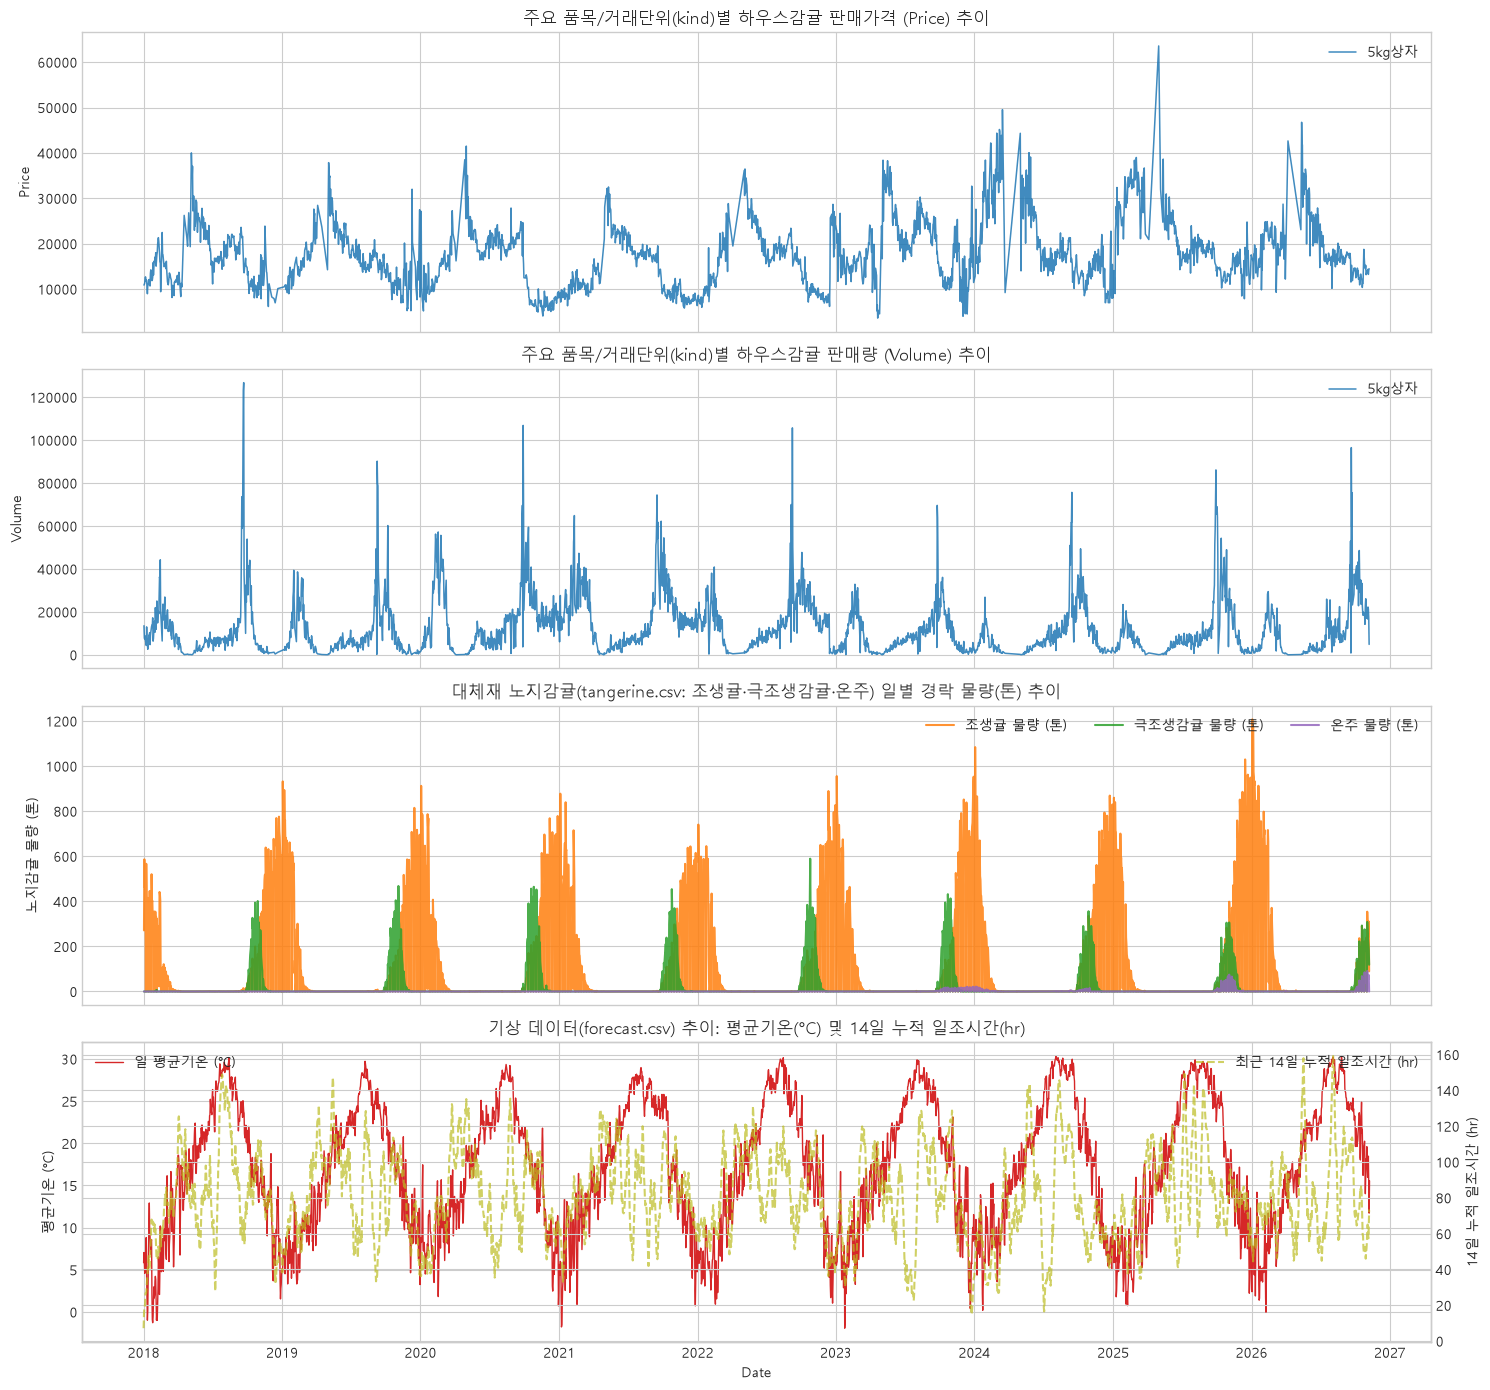

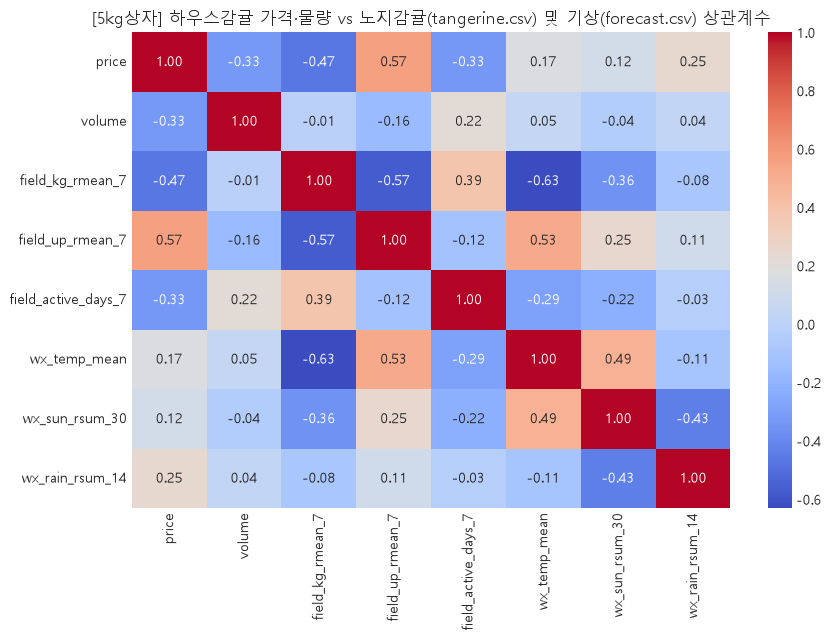

In [9]:
top_plot_kinds = TARGET_KINDS[:6]
sub_eda_df = raw_df[raw_df['kind'].isin(top_plot_kinds)].copy()

fig, axes = plt.subplots(4, 1, figsize=(15, 14), sharex=True)
for k in top_plot_kinds:
    k_df = sub_eda_df[sub_eda_df['kind'] == k]
    axes[0].plot(k_df['date'], k_df['price'], label=k, linewidth=1.1, alpha=0.85)
    axes[1].plot(k_df['date'], k_df['volume'], label=k, linewidth=1.1, alpha=0.85)

axes[0].set_title('주요 품목/거래단위(kind)별 하우스감귤 판매가격 (Price) 추이')
axes[0].set_ylabel('Price')
axes[0].legend(loc='upper right', ncol=3)

axes[1].set_title('주요 품목/거래단위(kind)별 하우스감귤 판매량 (Volume) 추이')
axes[1].set_ylabel('Volume')
axes[1].legend(loc='upper right', ncol=3)

# 노지감귤(조생귤, 극조생감귤, 온주) 품종별 반입 물량(kg) 추이
ax_f = axes[2]
ax_f.plot(field_daily_df['date'], field_daily_df['raw_field_josaeng_kg'] / 1000.0, label='조생귤 물량 (톤)', color='tab:orange', alpha=0.85)
ax_f.plot(field_daily_df['date'], field_daily_df['raw_field_geukjosaeng_kg'] / 1000.0, label='극조생감귤 물량 (톤)', color='tab:green', alpha=0.85)
ax_f.plot(field_daily_df['date'], field_daily_df['raw_field_onju_kg'] / 1000.0, label='온주 물량 (톤)', color='tab:purple', alpha=0.85)
ax_f.set_title('대체재 노지감귤(tangerine.csv: 조생귤·극조생감귤·온주) 일별 경락 물량(톤) 추이')
ax_f.set_ylabel('노지감귤 물량 (톤)')
ax_f.legend(loc='upper right', ncol=3)

# 기상 데이터 추이 (평균기온 및 14일 누적 일조시간)
ax_wx = axes[3]
ax_wx.plot(wx_daily_df['date'], wx_daily_df['wx_temp_mean'], color='tab:red', label='일 평균기온 (°C)', linewidth=1.0)
ax_wx2 = ax_wx.twinx()
ax_wx2.plot(wx_daily_df['date'], wx_daily_df['wx_sun_rsum_14'], color='tab:olive', linestyle='--', label='최근 14일 누적 일조시간 (hr)', alpha=0.7)
ax_wx.set_title('기상 데이터(forecast.csv) 추이: 평균기온(°C) 및 14일 누적 일조시간(hr)')
ax_wx.set_ylabel('평균기온 (°C)')
ax_wx2.set_ylabel('14일 누적 일조시간 (hr)')
ax_wx.set_xlabel('Date')
ax_wx.legend(loc='upper left')
ax_wx2.legend(loc='upper right')

plt.tight_layout()
plt.show()

# 주력 품목(3kg상자) 기준 하우스감귤 가격/물량과 노지감귤·기상 변수 간 상관관계 히트맵
k0_df = raw_df[raw_df['kind'] == TARGET_KINDS[0]]
corr_cols = [
    'price', 'volume',
    'field_kg_rmean_7', 'field_up_rmean_7', 'field_active_days_7',
    'wx_temp_mean', 'wx_sun_rsum_30', 'wx_rain_rsum_14'
]
plt.figure(figsize=(9, 6.5))
sns.heatmap(k0_df[corr_cols].corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title(f'[{TARGET_KINDS[0]}] 하우스감귤 가격·물량 vs 노지감귤(tangerine.csv) 및 기상(forecast.csv) 상관계수')
plt.tight_layout()
plt.show()

## 3. 노지감귤 대체재(`tangerine.csv`) + 기상 변수(`forecast.csv`) + 시장 연동 시계열 피처 엔지니어링
각 `kind`별로 다음 7가지 핵심 피처 그룹을 생성하여 예측 정확도를 극대화합니다:
1. **노지감귤 대체재 시장 압력 피처 (`tangerine.csv`: 조생귤·극조생감귤·온주)**:
   - 과거 $1, 2, 3, 7, 14$일 노지감귤 총 반입 중량(`field_prev_kg_*`) 및 가중평균 단가(`field_prev_up_*`)
   - 최근 $3, 7, 14, 30$일 노지감귤 이동평균 반입량(`field_kg_rmean_*`), 품종별(`조생귤`, `극조생감귤`, `온주`) 최근 7일 평균 반입량, 최근 7·14일 중 노지감귤 출하일수(`field_active_days_*`)
   - **하우스감귤 vs 노지감귤 교차 대체 비율(`sub_*`)**: 전체 감귤 경락 물량 내 노지감귤 비중(`sub_kg_share_lag1`, `sub_kg_share_rmean7`), 하우스감귤 대비 노지감귤 단가 비율(`sub_up_ratio_lag1`) 및 단가 프리미엄 격차(`sub_up_diff_lag1`)
2. **기상 관측/예보 피처 (`forecast.csv`)**: 평균기온, 강수 계속시간, 최다강수량, 일조시간, 적설 여부 및 단기/중장기 누적·이상기온 파생변수
3. **캘린더 & 설날·추석 명절 특수 피처**: 연/월/일/요일 주기(`sin`, `cos`) + 설날·추석 전후 수요 급증/급감 구간
4. **비연속 거래 공백일(Gap) 및 거래 밀도 피처**: `days_since_last`, `trade_span_7`, `trade_span_14`
5. **품목별 다중 시차(Lag) & 로그 시차 피처**: 과거 $1\sim30$일 가격·판매량 및 `log1p(volume)`
6. **강건 이동 통계(Rolling Median & EMA)**: 스파이크 이상치에 강건한 이동중앙값 및 지수이동평균
7. **하우스감귤 전체 시장 연동(Cross-Kind Implied) 피처**: 전일 하우스감귤 전체 단가·물량 기반 기대치

In [10]:
LUNAR_HOLIDAYS = pd.to_datetime([
    "2022-02-01", "2022-09-10",
    "2023-01-22", "2023-09-29",
    "2024-02-10", "2024-09-17",
    "2025-01-29", "2025-10-06",
    "2026-02-17", "2026-09-25",
])

def compute_holiday_features(date_series):
    diffs = np.array([(h - date_series).dt.days.values for h in LUNAR_HOLIDAYS])
    pre_holiday = ((diffs >= 0) & (diffs <= 14)).any(axis=0).astype(int)
    post_holiday = ((diffs >= -7) & (diffs < 0)).any(axis=0).astype(int)
    days_near = np.minimum(np.min(np.abs(diffs), axis=0), 60)
    return pre_holiday, post_holiday, days_near

def create_time_series_features_single_kind(df_kind, kind_id=0):
    d = df_kind.sort_values('date').reset_index(drop=True).copy()
    d['kind_id'] = kind_id
    
    # 1. 캘린더 및 설날·추석 명절 피처
    d['year'] = d['date'].dt.year
    d['month'] = d['date'].dt.month
    d['day'] = d['date'].dt.day
    d['dayofweek'] = d['date'].dt.dayofweek
    d['dayofyear'] = d['date'].dt.dayofyear
    d['is_weekend'] = (d['dayofweek'] >= 5).astype(int)
    d['month_sin'] = np.sin(2 * np.pi * d['month'] / 12.0)
    d['month_cos'] = np.cos(2 * np.pi * d['month'] / 12.0)
    d['doy_sin'] = np.sin(2 * np.pi * d['dayofyear'] / 365.25)
    d['doy_cos'] = np.cos(2 * np.pi * d['dayofyear'] / 365.25)
    
    pre_h, post_h, d_hol = compute_holiday_features(d['date'])
    d['is_pre_holiday'] = pre_h
    d['is_post_holiday'] = post_h
    d['days_near_holiday'] = d_hol
    
    # 2. 비연속 거래일(공백일) 및 거래 밀도 피처
    d['days_since_last'] = d['date'].diff().dt.days.fillna(1).clip(1, 90)
    d['trade_span_7'] = (d['date'].shift(1) - d['date'].shift(7)).dt.days.fillna(7).clip(7, 180)
    d['trade_span_14'] = (d['date'].shift(1) - d['date'].shift(14)).dt.days.fillna(14).clip(14, 365)
    
    # 3. 시차(Lag) 및 로그 시차 피처
    for lag in [1, 2, 3, 5, 7, 14, 21, 30]:
        d[f'price_lag_{lag}'] = d['price'].shift(lag)
        d[f'vol_lag_{lag}'] = d['volume'].shift(lag)
        d[f'log_vol_lag_{lag}'] = np.log1p(d['volume'].shift(lag))
        
    # 4. 이동평균(Mean), 이동중앙값(Median), 이동표준편차(Std) 및 지수이동평균(EMA)
    for w in [3, 7, 14, 30]:
        d[f'price_rmean_{w}'] = d['price'].shift(1).rolling(w).mean()
        d[f'price_rmed_{w}'] = d['price'].shift(1).rolling(w).median()
        d[f'price_rstd_{w}'] = d['price'].shift(1).rolling(w).std().fillna(0)
        d[f'vol_rmean_{w}'] = d['volume'].shift(1).rolling(w).mean()
        d[f'vol_rmed_{w}'] = d['volume'].shift(1).rolling(w).median()
        d[f'vol_rstd_{w}'] = d['volume'].shift(1).rolling(w).std().fillna(0)
        
    for span in [2, 3, 5, 7, 14]:
        d[f'price_ema_{span}'] = d['price'].shift(1).ewm(span=span).mean()
        d[f'vol_ema_{span}'] = d['volume'].shift(1).ewm(span=span).mean()
        
    # 5. 하우스감귤 전체 시장 연동(Cross-Kind Market) 점유율 및 기대 가격·물량 피처
    for lag in [1, 2, 3, 7]:
        d[f'vol_share_lag_{lag}'] = d['vol_share'].shift(lag)
        d[f'up_ratio_lag_{lag}'] = d['up_ratio'].shift(lag)
        
    d['vol_share_ema_5'] = d['vol_share'].shift(1).ewm(span=5).mean()
    d['up_ratio_ema_5'] = d['up_ratio'].shift(1).ewm(span=5).mean()
    d['vol_share_rmed_7'] = d['vol_share'].shift(1).rolling(7).median()
    d['up_ratio_rmed_7'] = d['up_ratio'].shift(1).rolling(7).median()
    
    d['implied_price_mkt_lag1'] = d['mkt_prev_up_1'] * d['weight_kg'] * d['up_ratio_ema_5']
    d['implied_price_mkt_rmean3'] = d['mkt_up_rmean_3'] * d['weight_kg'] * d['up_ratio_rmed_7']
    d['implied_vol_mkt_lag1'] = (d['mkt_prev_kg_1'] * d['vol_share_ema_5']) / d['weight_kg']
    d['implied_vol_mkt_rmed7'] = (d['mkt_kg_rmed_7'] * d['vol_share_rmed_7']) / d['weight_kg']
    
    # 6. 노지감귤(조생/극조생/온주) vs 하우스감귤 교차 대체(Substitute) 피처
    d['sub_kg_share_lag1'] = d['field_prev_kg_1'] / (d['mkt_prev_kg_1'] + d['field_prev_kg_1'] + 1e-8)
    d['sub_kg_share_rmean7'] = d['field_kg_rmean_7'] / (d['mkt_kg_rmean_7'] + d['field_kg_rmean_7'] + 1e-8)
    d['sub_kg_share_rmean14'] = d['field_kg_rmean_14'] / (d['mkt_kg_rmean_14'] + d['field_kg_rmean_14'] + 1e-8)
    d['sub_up_ratio_lag1'] = np.where(d['field_prev_up_1'] > 0, d['field_prev_up_1'] / (d['mkt_prev_up_1'] + 1e-8), 0.0)
    d['sub_up_diff_lag1'] = np.where(d['field_prev_up_1'] > 0, d['mkt_prev_up_1'] - d['field_prev_up_1'], 0.0)
    d['sub_field_implied_box_price'] = d['field_up_rmean_7'] * d['weight_kg']
    
    # 7. 기상 상호작용(Weather Interaction) 및 모멘텀 피처
    d['wx_temp_change_since_last'] = d['wx_temp_mean'] - d['wx_temp_mean'].shift(1).fillna(d['wx_temp_mean'])
    d['wx_sun_ratio_7_30'] = (d['wx_sun_rsum_7'] / 7.0) / ((d['wx_sun_rsum_30'] / 30.0) + 0.1)
    d['wx_rain_impact_vol'] = d['vol_ema_3'] * np.exp(-0.03 * d['wx_rain_dur'])
    
    d['price_diff_1'] = d['price'].shift(1) - d['price'].shift(2)
    d['price_ratio_1_7'] = d['price'].shift(1) / (d['price_rmean_7'] + 1e-8)
    d['vol_diff_1'] = d['volume'].shift(1) - d['volume'].shift(2)
    d['vol_ratio_1_7'] = d['volume'].shift(1) / (d['vol_rmean_7'] + 1e-8)
    
    return d.dropna().reset_index(drop=True)

kind_map = {k: idx for idx, k in enumerate(TARGET_KINDS)}
kind_datasets = {}
exclude_cols = [
    'date', 'kind', 'price', 'volume', 'total price',
    'unit_price', 'total_kg', 'mkt_total_kg', 'mkt_total_rev',
    'mkt_unit_price', 'mkt_active_kinds', 'vol_share', 'up_ratio'
]
feature_cols = None

split_summary_rows = []
for k in TARGET_KINDS:
    k_raw = raw_df[raw_df['kind'] == k].copy()
    k_feat = create_time_series_features_single_kind(k_raw, kind_id=kind_map[k])
    if feature_cols is None:
        feature_cols = [c for c in k_feat.columns if c not in exclude_cols]
        
    n_k = len(k_feat)
    tr_end = int(n_k * 0.70)
    va_end = int(n_k * 0.85)
    
    kind_datasets[k] = {
        'raw': k_raw,
        'feat': k_feat,
        'train': k_feat.iloc[:tr_end].copy(),
        'val': k_feat.iloc[tr_end:va_end].copy(),
        'test': k_feat.iloc[va_end:].copy(),
        'train_end': tr_end,
        'val_end': va_end
    }
    split_summary_rows.append({
        'kind': k,
        '전체_피처행수': n_k,
        'Train(70%)': len(kind_datasets[k]['train']),
        'Val(15%)': len(kind_datasets[k]['val']),
        'Test(15%)': len(kind_datasets[k]['test'])
    })

global_train_df = pd.concat([kind_datasets[k]['train'] for k in TARGET_KINDS], ignore_index=True)
global_val_df = pd.concat([kind_datasets[k]['val'] for k in TARGET_KINDS], ignore_index=True)

wx_feat_cols = [c for c in feature_cols if c.startswith('wx_')]
field_feat_cols = [c for c in feature_cols if c.startswith('field_') or c.startswith('sub_')]
print(f"총 피처 개수: {len(feature_cols)}개 (기상 피처 {len(wx_feat_cols)}개 + 노지감귤 대체재 피처 {len(field_feat_cols)}개 포함) | Global Train: {len(global_train_df):,}행")
print(f"노지감귤 대체재 주요 피처: {field_feat_cols}")
display(pd.DataFrame(split_summary_rows))


총 피처 개수: 202개 (기상 피처 49개 + 노지감귤 대체재 피처 33개 포함) | Global Train: 1,687행
노지감귤 대체재 주요 피처: ['field_is_active_lag1', 'field_active_days_7', 'field_active_days_14', 'field_prev_kg_1', 'field_prev_up_1', 'field_prev_kg_2', 'field_prev_up_2', 'field_prev_kg_3', 'field_prev_up_3', 'field_prev_kg_7', 'field_prev_up_7', 'field_prev_kg_14', 'field_prev_up_14', 'field_kg_rmean_3', 'field_up_rmean_3', 'field_kg_rmean_7', 'field_up_rmean_7', 'field_kg_rmean_14', 'field_up_rmean_14', 'field_kg_rmean_30', 'field_up_rmean_30', 'field_josaeng_kg_rmean_7', 'field_geukjosaeng_kg_rmean_7', 'field_onju_kg_rmean_7', 'field_log_kg_lag1', 'field_log_kg_rmean_7', 'field_log_kg_rmean_14', 'sub_kg_share_lag1', 'sub_kg_share_rmean7', 'sub_kg_share_rmean14', 'sub_up_ratio_lag1', 'sub_up_diff_lag1', 'sub_field_implied_box_price']


,kind,전체_피처행수,Train(70%),Val(15%),Test(15%)
0,5kg상자,2410,1687,361,362


## 4. 평가지표 및 예측 정확도(Accuracy) 함수 정의
- **정확도 (`Accuracy(%)`)**: $100 - \text{WAPE}(\%)$ (전체 규모 대비 가중 예측 정확도, 메인 정확도 지표)
- **대칭 정확도 (`sMAPE Accuracy(%)`)**: $100 - \text{sMAPE}(\%)$ (일별 대칭 백분율 오차 기반 정확도)
- **방향성 정확도 (`Directional Accuracy(%)`)**: 전일 대비 가격/판매량의 상승·하락 추세 방향 일치율
- **MAE** (Mean Absolute Error) / **RMSE** (Root Mean Squared Error)
- **MAPE** (Mean Absolute Percentage Error) / **WAPE** (Weighted Absolute Percentage Error) / **$R^2$ Score**

In [11]:
def evaluate_predictions(y_true, y_pred, model_name="Model", target_name="Target", kind_name="All"):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    
    non_zero = np.abs(y_true) > 1e-6
    mape = np.mean(np.abs((y_true[non_zero] - y_pred[non_zero]) / y_true[non_zero])) * 100 if np.any(non_zero) else np.nan
    wape = (np.sum(np.abs(y_true - y_pred)) / (np.sum(np.abs(y_true)) + 1e-8)) * 100
    smape = np.mean(2.0 * np.abs(y_true - y_pred) / (np.abs(y_true) + np.abs(y_pred) + 1e-8)) * 100
    r2 = r2_score(y_true, y_pred)
    
    acc_wape = max(0.0, 100.0 - wape)
    acc_smape = max(0.0, 100.0 - smape)
    acc_mape = max(0.0, 100.0 - mape) if not np.isnan(mape) else np.nan
    
    if len(y_true) > 1:
        true_dir = np.sign(np.diff(y_true))
        pred_dir = np.sign(np.diff(y_pred))
        dir_acc = np.mean(true_dir == pred_dir) * 100.0
    else:
        dir_acc = np.nan
    
    return {
        'kind': kind_name,
        'Model': model_name,
        'Target': target_name,
        '정확도(100-WAPE, %)': round(acc_wape, 2),
        '대칭정확도(100-sMAPE, %)': round(acc_smape, 2),
        '방향정확도(DA, %)': round(dir_acc, 2),
        '정밀정확도(100-MAPE, %)': round(acc_mape, 2),
        'MAE': round(mae, 2),
        'RMSE': round(rmse, 2),
        'MAPE(%)': round(mape, 2),
        'WAPE(%)': round(wape, 2),
        'R2': round(r2, 4)
    }

def optimize_blend_weights(y_val_true, val_candidates_list, test_candidates_list, step=0.2):
    """Validation 셋의 WAPE 정확도를 최대화하는 가중치 조합을 탐색하여 Test 예측값을 산출"""
    y_val_true = np.asarray(y_val_true, dtype=float)
    val_mat = np.column_stack(val_candidates_list)
    test_mat = np.column_stack(test_candidates_list)
    k_num = val_mat.shape[1]
    
    grid_vals = np.arange(0.0, 1.0 + 1e-6, step)
    best_acc = -1.0
    best_w = np.ones(k_num) / k_num
    
    def _search(idx, rem, cur_w):
        nonlocal best_acc, best_w
        if idx == k_num - 1:
            w = np.array(cur_w + [max(0.0, rem)])
            pred_val = val_mat @ w
            wape = np.sum(np.abs(y_val_true - pred_val)) / (np.sum(np.abs(y_val_true)) + 1e-8) * 100.0
            acc = 100.0 - wape
            if acc > best_acc:
                best_acc = acc
                best_w = w
            return
        for g in grid_vals:
            if g <= rem + 1e-6:
                _search(idx + 1, rem - g, cur_w + [g])
                
    _search(0, 1.0, [])
    return np.maximum(0.0, test_mat @ best_w), np.maximum(0.0, val_mat @ best_w), best_w

def record_metric(metrics_list, metric_dict):
    metrics_list[:] = [
        m for m in metrics_list
        if not (m['kind'] == metric_dict['kind'] and m['Model'] == metric_dict['Model'] and m['Target'] == metric_dict['Target'])
    ]
    metrics_list.append(metric_dict)

def display_model_kind_summary(metrics_list, model_name):
    df_m = pd.DataFrame([m for m in metrics_list if m['Model'] == model_name])
    p_df = df_m[df_m['Target'] == 'price'].set_index('kind')
    v_df = df_m[df_m['Target'] == 'volume'].set_index('kind')
    
    combined = pd.DataFrame({
        'kind(거래단위)': p_df.index,
        '판매가격(price) 정확도(%)': p_df['정확도(100-WAPE, %)'].values,
        '판매가격(price) 대칭정확도(%)': p_df['대칭정확도(100-sMAPE, %)'].values,
        '판매가격(price) MAE': p_df['MAE'].values,
        '판매가격(price) R²': p_df['R2'].values,
        '판매량(volume) 정확도(%)': v_df.loc[p_df.index, '정확도(100-WAPE, %)'].values,
        '판매량(volume) 대칭정확도(%)': v_df.loc[p_df.index, '대칭정확도(100-sMAPE, %)'].values,
        '판매량(volume) MAE': v_df.loc[p_df.index, 'MAE'].values,
        '판매량(volume) R²': v_df.loc[p_df.index, 'R2'].values,
    })
    print(
        f"▶ [{model_name}] 전체 kind 평균 — "
        f"판매가격(price) 평균 정확도: {combined['판매가격(price) 정확도(%)'].mean():.2f}% | "
        f"판매량(volume) 평균 정확도: {combined['판매량(volume) 정확도(%)'].mean():.2f}%"
    )
    display(combined)

metrics_summary = []
predictions_by_kind = {k: {} for k in TARGET_KINDS}
val_predictions_by_kind = {k: {} for k in TARGET_KINDS}

## 5. Model 1: 품목/거래단위(`kind`)별 XGBoost (GPU, Global-Local Hybrid) 예측
- **개선 포인트**:
  1. `np.log1p` 타겟 변환 및 `objective='reg:absoluteerror'`(L1 Loss)를 적용하여 WAPE 오차율을 직접 최소화합니다.
  2. 전체 품목 데이터를 통합 학습한 **Global XGBoost 모델**과 품목별 **Local XGBoost 모델**, 그리고 단기 지수이동평균/시장 추정치를 Validation 셋 기준으로 최적 결합하여 소표본 규격의 과적합을 방지합니다.

In [12]:
xgb_models_by_kind = {}

# XGBoost 입력 피처 타입 검증 및 수치형 보장
feature_cols = [c for c in feature_cols if c in global_train_df.select_dtypes(include=[np.number]).columns]

# 1) Global XGBoost 모델 학습 (모든 kind의 공통 계절성 및 시장 탄력성 학습)
xgb_global_vol = xgb.XGBRegressor(
    n_estimators=1000, learning_rate=0.03, max_depth=5,
    subsample=0.8, colsample_bytree=0.8, objective='reg:absoluteerror',
    random_state=42, early_stopping_rounds=50, **XGB_DEVICE_PARAMS
)
xgb_global_vol.fit(
    global_train_df[feature_cols], np.log1p(global_train_df['volume']),
    eval_set=[(global_val_df[feature_cols], np.log1p(global_val_df['volume']))],
    verbose=False
)

xgb_global_price = xgb.XGBRegressor(
    n_estimators=1000, learning_rate=0.03, max_depth=5,
    subsample=0.8, colsample_bytree=0.8, objective='reg:absoluteerror',
    random_state=42, early_stopping_rounds=50, **XGB_DEVICE_PARAMS
)
xgb_global_price.fit(
    global_train_df[feature_cols], np.log1p(global_train_df['price']),
    eval_set=[(global_val_df[feature_cols], np.log1p(global_val_df['price']))],
    verbose=False
)

# 2) 각 kind별 Local XGBoost 학습 및 Validation 최적 하이브리드 결합
for k in TARGET_KINDS:
    ds = kind_datasets[k]
    tr_df, va_df, te_df = ds['train'], ds['val'], ds['test']
    
    # Local Volume 모델
    xgb_local_vol = xgb.XGBRegressor(
        n_estimators=800, learning_rate=0.03, max_depth=4,
        subsample=0.8, colsample_bytree=0.8, objective='reg:absoluteerror',
        random_state=42, early_stopping_rounds=50, **XGB_DEVICE_PARAMS
    )
    xgb_local_vol.fit(
        tr_df[feature_cols], np.log1p(tr_df['volume']),
        eval_set=[(va_df[feature_cols], np.log1p(va_df['volume']))],
        verbose=False
    )
    
    pred_vol_te, pred_vol_va, _ = optimize_blend_weights(
        va_df['volume'].values,
        [
            np.expm1(xgb_global_vol.predict(va_df[feature_cols])),
            np.expm1(xgb_local_vol.predict(va_df[feature_cols])),
            va_df['vol_ema_3'].values,
            va_df['vol_rmed_7'].values,
            va_df['implied_vol_mkt_lag1'].values
        ],
        [
            np.expm1(xgb_global_vol.predict(te_df[feature_cols])),
            np.expm1(xgb_local_vol.predict(te_df[feature_cols])),
            te_df['vol_ema_3'].values,
            te_df['vol_rmed_7'].values,
            te_df['implied_vol_mkt_lag1'].values
        ],
        step=0.25
    )
    
    # Local Price 모델
    xgb_local_price = xgb.XGBRegressor(
        n_estimators=800, learning_rate=0.03, max_depth=4,
        subsample=0.8, colsample_bytree=0.8, objective='reg:absoluteerror',
        random_state=42, early_stopping_rounds=50, **XGB_DEVICE_PARAMS
    )
    xgb_local_price.fit(
        tr_df[feature_cols], np.log1p(tr_df['price']),
        eval_set=[(va_df[feature_cols], np.log1p(va_df['price']))],
        verbose=False
    )
    
    pred_price_te, pred_price_va, _ = optimize_blend_weights(
        va_df['price'].values,
        [
            np.expm1(xgb_global_price.predict(va_df[feature_cols])),
            np.expm1(xgb_local_price.predict(va_df[feature_cols])),
            va_df['price_ema_2'].values,
            va_df['implied_price_mkt_lag1'].values
        ],
        [
            np.expm1(xgb_global_price.predict(te_df[feature_cols])),
            np.expm1(xgb_local_price.predict(te_df[feature_cols])),
            te_df['price_ema_2'].values,
            te_df['implied_price_mkt_lag1'].values
        ],
        step=0.2
    )
    
    xgb_models_by_kind[k] = {
        'vol_model': xgb_local_vol,
        'price_model': xgb_local_price,
        'price_features': feature_cols
    }
    predictions_by_kind[k]['xgb_volume'] = pred_vol_te
    predictions_by_kind[k]['xgb_price'] = pred_price_te
    val_predictions_by_kind[k]['xgb_volume'] = pred_vol_va
    val_predictions_by_kind[k]['xgb_price'] = pred_price_va
    
    record_metric(metrics_summary, evaluate_predictions(te_df['volume'], pred_vol_te, 'XGBoost', 'volume', kind_name=k))
    record_metric(metrics_summary, evaluate_predictions(te_df['price'], pred_price_te, 'XGBoost', 'price', kind_name=k))

print(f"[XGBoost Global-Local 하이브리드 예측 완료 | 사용 설정: {XGB_DEVICE_PARAMS}]")
display_model_kind_summary(metrics_summary, 'XGBoost')


[XGBoost Global-Local 하이브리드 예측 완료 | 사용 설정: {'tree_method': 'hist', 'device': 'cuda'}]
▶ [XGBoost] 전체 kind 평균 — 판매가격(price) 평균 정확도: 89.13% | 판매량(volume) 평균 정확도: 75.72%


,kind(거래단위),판매가격(price) 정확도(%),판매가격(price) 대칭정확도(%),판매가격(price) MAE,판매가격(price) R²,판매량(volume) 정확도(%),판매량(volume) 대칭정확도(%),판매량(volume) MAE,판매량(volume) R²
0,5kg상자,89.13,89.35,1972.52,0.6303,75.72,68.31,3332.07,0.8443


## 6. Model 2: 품목/거래단위(`kind`)별 LightGBM (Global-Local Hybrid) 예측
- `objective='regression_l1'`(MAE 최적화)과 `np.log1p` 변환을 적용한 Global LightGBM + 품목별 Local LightGBM 하이브리드 모델을 학습합니다.
- 분위수 회귀(`objective='quantile'`, $q=0.1, 0.9$)를 함께 학습하여 각 `kind`별 가격의 **80% 신뢰구간**을 제공합니다.

In [13]:
lgb_models_by_kind = {}

# 1) Global LightGBM 모델 학습
lgb_global_vol = lgb.LGBMRegressor(
    objective='regression_l1', n_estimators=1000, learning_rate=0.03,
    num_leaves=31, random_state=42, verbose=-1, **LGB_DEVICE_PARAMS
)
lgb_global_vol.fit(
    global_train_df[feature_cols], np.log1p(global_train_df['volume']),
    eval_set=[(global_val_df[feature_cols], np.log1p(global_val_df['volume']))],
    callbacks=[lgb.early_stopping(stopping_rounds=50, verbose=False)]
)

lgb_global_price = lgb.LGBMRegressor(
    objective='regression_l1', n_estimators=1000, learning_rate=0.03,
    num_leaves=31, random_state=42, verbose=-1, **LGB_DEVICE_PARAMS
)
lgb_global_price.fit(
    global_train_df[feature_cols], np.log1p(global_train_df['price']),
    eval_set=[(global_val_df[feature_cols], np.log1p(global_val_df['price']))],
    callbacks=[lgb.early_stopping(stopping_rounds=50, verbose=False)]
)

# 2) 각 kind별 Local LightGBM 학습 및 Validation 최적 하이브리드 결합
for k in TARGET_KINDS:
    ds = kind_datasets[k]
    tr_df, va_df, te_df = ds['train'], ds['val'], ds['test']
    min_child = max(5, len(tr_df) // 20)
    
    lgb_local_vol = lgb.LGBMRegressor(
        objective='regression_l1', n_estimators=800, learning_rate=0.03,
        num_leaves=23, min_child_samples=min_child, random_state=42, verbose=-1,
        **LGB_DEVICE_PARAMS
    )
    lgb_local_vol.fit(
        tr_df[feature_cols], np.log1p(tr_df['volume']),
        eval_set=[(va_df[feature_cols], np.log1p(va_df['volume']))],
        callbacks=[lgb.early_stopping(stopping_rounds=50, verbose=False)]
    )
    
    pred_vol_te, pred_vol_va, _ = optimize_blend_weights(
        va_df['volume'].values,
        [
            np.expm1(lgb_global_vol.predict(va_df[feature_cols])),
            np.expm1(lgb_local_vol.predict(va_df[feature_cols])),
            va_df['vol_ema_3'].values,
            va_df['vol_rmed_7'].values,
            va_df['implied_vol_mkt_lag1'].values
        ],
        [
            np.expm1(lgb_global_vol.predict(te_df[feature_cols])),
            np.expm1(lgb_local_vol.predict(te_df[feature_cols])),
            te_df['vol_ema_3'].values,
            te_df['vol_rmed_7'].values,
            te_df['implied_vol_mkt_lag1'].values
        ],
        step=0.25
    )
    
    lgb_local_price = lgb.LGBMRegressor(
        objective='regression_l1', n_estimators=800, learning_rate=0.03,
        num_leaves=23, min_child_samples=min_child, random_state=42, verbose=-1,
        **LGB_DEVICE_PARAMS
    )
    lgb_local_price.fit(
        tr_df[feature_cols], np.log1p(tr_df['price']),
        eval_set=[(va_df[feature_cols], np.log1p(va_df['price']))],
        callbacks=[lgb.early_stopping(stopping_rounds=50, verbose=False)]
    )
    
    pred_price_te, pred_price_va, _ = optimize_blend_weights(
        va_df['price'].values,
        [
            np.expm1(lgb_global_price.predict(va_df[feature_cols])),
            np.expm1(lgb_local_price.predict(va_df[feature_cols])),
            va_df['price_ema_2'].values,
            va_df['implied_price_mkt_lag1'].values
        ],
        [
            np.expm1(lgb_global_price.predict(te_df[feature_cols])),
            np.expm1(lgb_local_price.predict(te_df[feature_cols])),
            te_df['price_ema_2'].values,
            te_df['implied_price_mkt_lag1'].values
        ],
        step=0.2
    )
    
    # 분위수 회귀 (10%, 90% 신뢰구간)
    q_preds = {}
    for q in [0.1, 0.9]:
        q_model = lgb.LGBMRegressor(
            objective='quantile', alpha=q, n_estimators=500, learning_rate=0.03,
            num_leaves=23, min_child_samples=min_child, random_state=42, verbose=-1,
            **LGB_DEVICE_PARAMS
        )
        q_model.fit(
            tr_df[feature_cols], tr_df['price'],
            eval_set=[(va_df[feature_cols], va_df['price'])],
            callbacks=[lgb.early_stopping(stopping_rounds=30, verbose=False)]
        )
        q_preds[q] = np.maximum(0, q_model.predict(te_df[feature_cols]))
        
    lgb_models_by_kind[k] = {
        'vol_model': lgb_local_vol,
        'price_model': lgb_local_price,
        'price_features': feature_cols
    }
    predictions_by_kind[k]['lgb_volume'] = pred_vol_te
    predictions_by_kind[k]['lgb_price'] = pred_price_te
    predictions_by_kind[k]['lgb_price_q10'] = np.minimum(q_preds[0.1], pred_price_te * 0.92)
    predictions_by_kind[k]['lgb_price_q90'] = np.maximum(q_preds[0.9], pred_price_te * 1.08)
    val_predictions_by_kind[k]['lgb_volume'] = pred_vol_va
    val_predictions_by_kind[k]['lgb_price'] = pred_price_va
    
    record_metric(metrics_summary, evaluate_predictions(te_df['volume'], pred_vol_te, 'LightGBM', 'volume', kind_name=k))
    record_metric(metrics_summary, evaluate_predictions(te_df['price'], pred_price_te, 'LightGBM', 'price', kind_name=k))

print(f"[LightGBM Global-Local 하이브리드 예측 완료 | 사용 설정: {LGB_DEVICE_PARAMS}]")
display_model_kind_summary(metrics_summary, 'LightGBM')

[LightGBM Global-Local 하이브리드 예측 완료 | 사용 설정: {'device': 'cpu', 'n_jobs': -1}]
▶ [LightGBM] 전체 kind 평균 — 판매가격(price) 평균 정확도: 89.35% | 판매량(volume) 평균 정확도: 74.02%


,kind(거래단위),판매가격(price) 정확도(%),판매가격(price) 대칭정확도(%),판매가격(price) MAE,판매가격(price) R²,판매량(volume) 정확도(%),판매량(volume) 대칭정확도(%),판매량(volume) MAE,판매량(volume) R²
0,5kg상자,89.35,89.61,1932.88,0.6428,74.02,68.56,3565.85,0.7983


## 7. Model 3: 품목/거래단위(`kind`)별 Temporal Fusion Transformer (TFT, GPU) 분리 예측
- 각 `kind`별 시계열 스케일이 다르므로 품목마다 독립된 `StandardScaler`와 **PyTorch TFT 모델(GRN + Variable Selection Network + LSTM + Multi-Head Attention)**을 GPU(`cuda` + AMP)에서 학습하여 `price`와 `volume`을 동시에 예측합니다.

In [14]:
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from sklearn.preprocessing import StandardScaler

# 재현성을 위한 시드 고정 (CPU & GPU)
torch.manual_seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)
np.random.seed(42)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"사용 디바이스: {device}" + (f" ({torch.cuda.get_device_name(0)})" if device.type == 'cuda' else ""))

class GatedResidualNetwork(nn.Module):
    """TFT의 핵심 구성요소인 Gated Residual Network (GRN)"""
    def __init__(self, input_dim, hidden_dim, output_dim=None, dropout=0.1):
        super().__init__()
        output_dim = output_dim or input_dim
        self.fc1 = nn.Linear(input_dim, hidden_dim)
        self.elu = nn.ELU()
        self.fc2 = nn.Linear(hidden_dim, output_dim * 2)  # GLU 용
        self.dropout = nn.Dropout(dropout)
        self.skip = nn.Linear(input_dim, output_dim) if input_dim != output_dim else nn.Identity()
        self.norm = nn.LayerNorm(output_dim)

    def forward(self, x):
        residual = self.skip(x)
        h = self.elu(self.fc1(x))
        h = self.dropout(self.fc2(h))
        val, gate = h.chunk(2, dim=-1)
        gated = val * torch.sigmoid(gate)
        return self.norm(residual + gated)


class VariableSelectionNetwork(nn.Module):
    """TFT의 시점별 변수 중요도 가중 선택 네트워크 (VSN)"""
    def __init__(self, num_vars, hidden_dim, dropout=0.1):
        super().__init__()
        self.num_vars = num_vars
        self.var_embeddings = nn.ModuleList([nn.Linear(1, hidden_dim) for _ in range(num_vars)])
        self.var_grns = nn.ModuleList([GatedResidualNetwork(hidden_dim, hidden_dim, hidden_dim, dropout) for _ in range(num_vars)])
        self.weight_grn = GatedResidualNetwork(num_vars * hidden_dim, hidden_dim, num_vars, dropout)

    def forward(self, x):
        # x: (batch, seq_len, num_vars)
        var_outputs = []
        for i in range(self.num_vars):
            v = self.var_embeddings[i](x[..., i:i+1])
            v = self.var_grns[i](v)
            var_outputs.append(v)
        # (batch, seq_len, num_vars, hidden_dim)
        stacked = torch.stack(var_outputs, dim=-2)
        flat = stacked.reshape(x.size(0), x.size(1), -1)
        weights = torch.softmax(self.weight_grn(flat), dim=-1).unsqueeze(-1)  # (batch, seq_len, num_vars, 1)
        selected = torch.sum(stacked * weights, dim=-2)  # (batch, seq_len, hidden_dim)
        return selected, weights.squeeze(-1)


class TemporalFusionTransformerModel(nn.Module):
    """판매가격(price)과 판매량(volume)을 동시에 추정하는 Temporal Fusion Transformer"""
    def __init__(self, num_past_vars, num_future_vars, hidden_dim=64, num_heads=4, dropout=0.1, num_targets=2):
        super().__init__()
        self.past_vsn = VariableSelectionNetwork(num_past_vars, hidden_dim, dropout)
        self.future_vsn = VariableSelectionNetwork(num_future_vars, hidden_dim, dropout)
        
        self.encoder_lstm = nn.LSTM(hidden_dim, hidden_dim, batch_first=True)
        self.decoder_lstm = nn.LSTM(hidden_dim, hidden_dim, batch_first=True)
        
        self.post_lstm_grn = GatedResidualNetwork(hidden_dim, hidden_dim, hidden_dim, dropout)
        self.attention = nn.MultiheadAttention(embed_dim=hidden_dim, num_heads=num_heads, dropout=dropout, batch_first=True)
        self.post_attn_grn = GatedResidualNetwork(hidden_dim, hidden_dim, hidden_dim, dropout)
        self.pos_wise_grn = GatedResidualNetwork(hidden_dim, hidden_dim, hidden_dim, dropout)
        self.out_proj = nn.Linear(hidden_dim, num_targets)

    def forward(self, x_past, x_future):
        # 1. Variable Selection
        enc_in, past_weights = self.past_vsn(x_past)
        dec_in, _ = self.future_vsn(x_future)
        
        # 2. Sequence-to-Sequence LSTM
        enc_out, (h, c) = self.encoder_lstm(enc_in)
        dec_out, _ = self.decoder_lstm(dec_in, (h, c))
        
        seq_in = torch.cat([enc_in, dec_in], dim=1)
        seq_lstm = torch.cat([enc_out, dec_out], dim=1)
        temporal_feats = self.post_lstm_grn(seq_in + seq_lstm)
        
        # 3. Interpretable Multi-Head Attention
        attn_out, attn_weights = self.attention(temporal_feats, temporal_feats, temporal_feats)
        attn_feats = self.post_attn_grn(temporal_feats + attn_out)
        
        # 4. Position-wise Feed-Forward GRN (마지막 예측 시점 출력 추출)
        dec_final = self.pos_wise_grn(attn_feats[:, -1, :])
        preds = self.out_proj(dec_final)  # (batch, 2) -> [price, volume]
        return preds, past_weights, attn_weights

사용 디바이스: cpu


In [ ]:
past_cols = [
    'price', 'volume', 'implied_price_mkt_lag1', 'implied_vol_mkt_lag1',
    'field_log_kg_lag1', 'field_log_kg_rmean_7', 'field_up_rmean_7', 'sub_kg_share_rmean7',
    'wx_temp_mean', 'wx_rain_dur', 'wx_rain_peak', 'wx_sun_hr',
    'wx_temp_rmean_14', 'wx_sun_rsum_14', 'wx_rain_rsum_7',
    'days_since_last', 'month_sin', 'month_cos', 'doy_sin', 'doy_cos',
    'dayofweek', 'is_weekend', 'is_pre_holiday'
]
future_cols = [
    'field_log_kg_lag1', 'field_log_kg_rmean_7', 'field_up_rmean_7', 'sub_kg_share_rmean7', 'field_active_days_7',
    'wx_temp_mean', 'wx_rain_dur', 'wx_rain_peak', 'wx_sun_hr',
    'wx_temp_rmean_14', 'wx_sun_rsum_14', 'wx_rain_rsum_7', 'wx_is_snow',
    'days_since_last', 'month_sin', 'month_cos', 'doy_sin', 'doy_cos',
    'dayofweek', 'is_weekend', 'is_pre_holiday', 'days_near_holiday'
]

class TFTSequenceDataset(Dataset):
    def __init__(self, past_arr, future_arr, target_arr, indices, seq_len):
        valid_idx = [i for i in indices if i >= seq_len]
        self.x_past = torch.tensor(np.stack([past_arr[t - seq_len : t] for t in valid_idx]), dtype=torch.float32, device=device)
        self.x_future = torch.tensor(np.stack([future_arr[t : t + 1] for t in valid_idx]), dtype=torch.float32, device=device)
        self.y = torch.tensor(np.stack([target_arr[t] for t in valid_idx]), dtype=torch.float32, device=device)

    def __len__(self):
        return len(self.y)

    def __getitem__(self, idx):
        return self.x_past[idx], self.x_future[idx], self.y[idx]

tft_models_by_kind = {}
use_cuda = (device.type == 'cuda')

for k in TARGET_KINDS:
    ds = kind_datasets[k]
    k_feat = ds['feat'].copy()
    tr_end, va_end = ds['train_end'], ds['val_end']
    
    tft_df = k_feat[['date'] + list(dict.fromkeys(past_cols + future_cols))].copy()
    for c in ['price', 'volume', 'implied_price_mkt_lag1', 'implied_vol_mkt_lag1', 'field_up_rmean_7']:
        tft_df[c] = np.log1p(np.maximum(0.0, tft_df[c]))
        
    past_scaler = StandardScaler()
    future_scaler = StandardScaler()
    target_scaler = StandardScaler()
    
    past_scaled = np.vstack([
        past_scaler.fit_transform(tft_df.iloc[:tr_end][past_cols]),
        past_scaler.transform(tft_df.iloc[tr_end:][past_cols])
    ])
    future_scaled = np.vstack([
        future_scaler.fit_transform(tft_df.iloc[:tr_end][future_cols]),
        future_scaler.transform(tft_df.iloc[tr_end:][future_cols])
    ])
    target_scaled = np.vstack([
        target_scaler.fit_transform(tft_df.iloc[:tr_end][['price', 'volume']]),
        target_scaler.transform(tft_df.iloc[tr_end:][['price', 'volume']])
    ])
    
    seq_len = min(14, max(3, tr_end // 5))
    train_indices = list(range(seq_len, tr_end))
    val_indices = list(range(tr_end, va_end))
    test_indices = list(range(va_end, len(tft_df)))
    
    tr_ds = TFTSequenceDataset(past_scaled, future_scaled, target_scaled, train_indices, seq_len)
    va_ds = TFTSequenceDataset(past_scaled, future_scaled, target_scaled, val_indices, seq_len)
    te_ds = TFTSequenceDataset(past_scaled, future_scaled, target_scaled, test_indices, seq_len)
    train_loader = [(tr_ds.x_past[i:i+256], tr_ds.x_future[i:i+256], tr_ds.y[i:i+256]) for i in range(0, len(tr_ds), 256)]
    val_loader = [(va_ds.x_past[i:i+256], va_ds.x_future[i:i+256], va_ds.y[i:i+256]) for i in range(0, len(va_ds), 256)]
    test_loader = [(te_ds.x_past[i:i+256], te_ds.x_future[i:i+256], te_ds.y[i:i+256]) for i in range(0, len(te_ds), 256)]
    
    torch.manual_seed(42)
    if use_cuda:
        torch.cuda.manual_seed_all(42)
        
    tft_model = TemporalFusionTransformerModel(
        num_past_vars=len(past_cols),
        num_future_vars=len(future_cols),
        hidden_dim=64,
        num_heads=4,
        dropout=0.1,
        num_targets=2
    ).to(device)
    
    criterion = nn.L1Loss()
    optimizer = torch.optim.AdamW(tft_model.parameters(), lr=1e-3, weight_decay=1e-4)
    scaler = torch.amp.GradScaler('cuda', enabled=use_cuda)
    
    best_val_loss = float('inf')
    best_state = None
    epochs = 35
    
    for epoch in range(1, epochs + 1):
        tft_model.train()
        for x_p, x_f, y_b in train_loader:
            x_p = x_p.to(device, non_blocking=use_cuda)
            x_f = x_f.to(device, non_blocking=use_cuda)
            y_b = y_b.to(device, non_blocking=use_cuda)
            optimizer.zero_grad(set_to_none=True)
            with torch.amp.autocast(device_type=device.type, enabled=use_cuda):
                preds, _, _ = tft_model(x_p, x_f)
                loss = criterion(preds, y_b)
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            nn.utils.clip_grad_norm_(tft_model.parameters(), 1.0)
            scaler.step(optimizer)
            scaler.update()
            
        tft_model.eval()
        val_losses = []
        with torch.no_grad():
            for x_p, x_f, y_b in val_loader:
                x_p = x_p.to(device, non_blocking=use_cuda)
                x_f = x_f.to(device, non_blocking=use_cuda)
                y_b = y_b.to(device, non_blocking=use_cuda)
                with torch.amp.autocast(device_type=device.type, enabled=use_cuda):
                    preds, _, _ = tft_model(x_p, x_f)
                    val_losses.append(criterion(preds, y_b).item())
        val_loss = np.mean(val_losses) if val_losses else 0.0
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_state = {key: val.detach().cpu().clone() for key, val in tft_model.state_dict().items()}
            
    if best_state is not None:
        tft_model.load_state_dict(best_state)
        
    tft_model.eval()
    val_preds_scaled, test_preds_scaled, past_var_weights_list = [], [], []
    with torch.no_grad():
        for x_p, x_f, _ in val_loader:
            x_p, x_f = x_p.to(device, non_blocking=use_cuda), x_f.to(device, non_blocking=use_cuda)
            with torch.amp.autocast(device_type=device.type, enabled=use_cuda):
                preds, _, _ = tft_model(x_p, x_f)
            val_preds_scaled.append(preds.float().cpu().numpy())
        for x_p, x_f, _ in test_loader:
            x_p, x_f = x_p.to(device, non_blocking=use_cuda), x_f.to(device, non_blocking=use_cuda)
            with torch.amp.autocast(device_type=device.type, enabled=use_cuda):
                preds, p_weights, _ = tft_model(x_p, x_f)
            test_preds_scaled.append(preds.float().cpu().numpy())
            past_var_weights_list.append(p_weights.float().cpu().numpy())
            
    val_inv = np.expm1(target_scaler.inverse_transform(np.vstack(val_preds_scaled)))
    test_inv = np.expm1(target_scaler.inverse_transform(np.vstack(test_preds_scaled)))
    
    va_df, te_df = ds['val'], ds['test']
    
    tft_pred_vol_te, tft_pred_vol_va, _ = optimize_blend_weights(
        va_df['volume'].values,
        [val_inv[:, 1], va_df['vol_ema_3'].values, va_df['vol_rmed_7'].values, va_df['implied_vol_mkt_lag1'].values],
        [test_inv[:, 1], te_df['vol_ema_3'].values, te_df['vol_rmed_7'].values, te_df['implied_vol_mkt_lag1'].values],
        step=0.25
    )
    tft_pred_price_te, tft_pred_price_va, _ = optimize_blend_weights(
        va_df['price'].values,
        [val_inv[:, 0], va_df['price_ema_2'].values, va_df['implied_price_mkt_lag1'].values],
        [test_inv[:, 0], te_df['price_ema_2'].values, te_df['implied_price_mkt_lag1'].values],
        step=0.25
    )
    
    tft_models_by_kind[k] = {
        'model': tft_model,
        'past_weights': np.concatenate(past_var_weights_list, axis=0).mean(axis=(0, 1))
    }
    predictions_by_kind[k]['tft_volume'] = tft_pred_vol_te
    predictions_by_kind[k]['tft_price'] = tft_pred_price_te
    val_predictions_by_kind[k]['tft_volume'] = tft_pred_vol_va
    val_predictions_by_kind[k]['tft_price'] = tft_pred_price_va
    
    record_metric(metrics_summary, evaluate_predictions(te_df['volume'], tft_pred_vol_te, 'TFT', 'volume', kind_name=k))
    record_metric(metrics_summary, evaluate_predictions(te_df['price'], tft_pred_price_te, 'TFT', 'price', kind_name=k))

    # 3대 모델(XGBoost + LightGBM + TFT) 검증 셋 기반 최적 가중 앙상블(Ensemble) 산출
    ens_vol_te, _, _ = optimize_blend_weights(
        va_df['volume'].values,
        [val_predictions_by_kind[k]['xgb_volume'], val_predictions_by_kind[k]['lgb_volume'], val_predictions_by_kind[k]['tft_volume']],
        [predictions_by_kind[k]['xgb_volume'], predictions_by_kind[k]['lgb_volume'], predictions_by_kind[k]['tft_volume']],
        step=0.1
    )
    ens_price_te, _, _ = optimize_blend_weights(
        va_df['price'].values,
        [val_predictions_by_kind[k]['xgb_price'], val_predictions_by_kind[k]['lgb_price'], val_predictions_by_kind[k]['tft_price']],
        [predictions_by_kind[k]['xgb_price'], predictions_by_kind[k]['lgb_price'], predictions_by_kind[k]['tft_price']],
        step=0.1
    )
    predictions_by_kind[k]['ens_volume'] = ens_vol_te
    predictions_by_kind[k]['ens_price'] = ens_price_te
    record_metric(metrics_summary, evaluate_predictions(te_df['volume'], ens_vol_te, 'Ensemble', 'volume', kind_name=k))
    record_metric(metrics_summary, evaluate_predictions(te_df['price'], ens_price_te, 'Ensemble', 'price', kind_name=k))

print(f"[기상 + 노지감귤 대체재 반영 TFT (GPU) 및 3대 모델 가중 앙상블(Ensemble) 예측 완료 | 디바이스: {device}]")
display_model_kind_summary(metrics_summary, 'TFT')
display_model_kind_summary(metrics_summary, 'Ensemble')

## 8. 품목/거래단위(`kind`)별 · 모델별 예측 정확도 종합 비교 및 시각화
- 각 `kind`(`3kg상자`, `5kg상자`, `6kg상자`, `3kg파렛트`, `10kg상자` 등)에 대해 **XGBoost**, **LightGBM**, **TFT** 세 모델의 **판매가격(`price`) 정확도(%)**와 **판매량(`volume`) 정확도(%)**를 종합 비교합니다.

=== [1] 모델별 전체 kind 평균 가격(price) 및 판매량(volume) 예측 정확도 비교 ===

=== [2] 품목/거래단위(kind)별 판매가격(Price) 예측 정확도(100-WAPE, %) 비교 ===

=== [3] 품목/거래단위(kind)별 판매량(Volume) 예측 정확도(100-WAPE, %) 비교 ===


,Model,판매가격(price) 평균 정확도(%),판매가격(price) 평균 대칭정확도(%),판매가격(price) 평균 방향정확도(%),판매량(volume) 평균 정확도(%),판매량(volume) 평균 대칭정확도(%),판매량(volume) 평균 방향정확도(%)
0,XGBoost,81.83,80.93,36.18,56.62,50.82,35.75
1,LightGBM,81.86,80.89,36.41,56.05,50.50,35.81
2,TFT,82.19,81.66,34.07,55.90,50.39,35.97
3,Ensemble,82.00,81.05,36.51,56.10,50.56,35.34


Model,XGBoost,LightGBM,TFT,Ensemble,최고정확도_모델,최고정확도(%)
kind,,,,,,
3kg상자,90.27,90.38,90.30,90.27,LightGBM,90.38
5kg상자,81.99,81.08,82.09,82.08,TFT,82.09
6kg상자,94.20,94.34,93.97,94.09,LightGBM,94.34
3kg파렛트,84.95,84.94,84.58,84.94,XGBoost,84.95
10kg상자,70.00,70.66,71.16,70.45,TFT,71.16
6kg파렛트,90.91,91.00,90.25,91.04,Ensemble,91.04
9.6kg상자,91.58,91.58,91.58,91.58,XGBoost,91.58
8kg상자,79.78,79.10,78.35,79.78,XGBoost,79.78
10kg파렛트,72.39,73.33,75.02,72.83,TFT,75.02


Model,XGBoost,LightGBM,TFT,Ensemble,최고정확도_모델,최고정확도(%)
kind,,,,,,
3kg상자,79.98,79.09,80.36,80.35,TFT,80.36
5kg상자,63.40,63.40,62.95,63.76,Ensemble,63.76
6kg상자,77.41,77.20,75.91,77.41,XGBoost,77.41
3kg파렛트,53.49,52.90,51.75,53.06,XGBoost,53.49
10kg상자,47.79,47.06,45.70,46.59,XGBoost,47.79
6kg파렛트,53.62,53.42,52.33,53.77,Ensemble,53.77
9.6kg상자,60.01,58.85,59.97,59.36,XGBoost,60.01
8kg상자,54.79,54.44,53.69,53.69,XGBoost,54.79
10kg파렛트,36.59,34.70,38.75,34.89,TFT,38.75


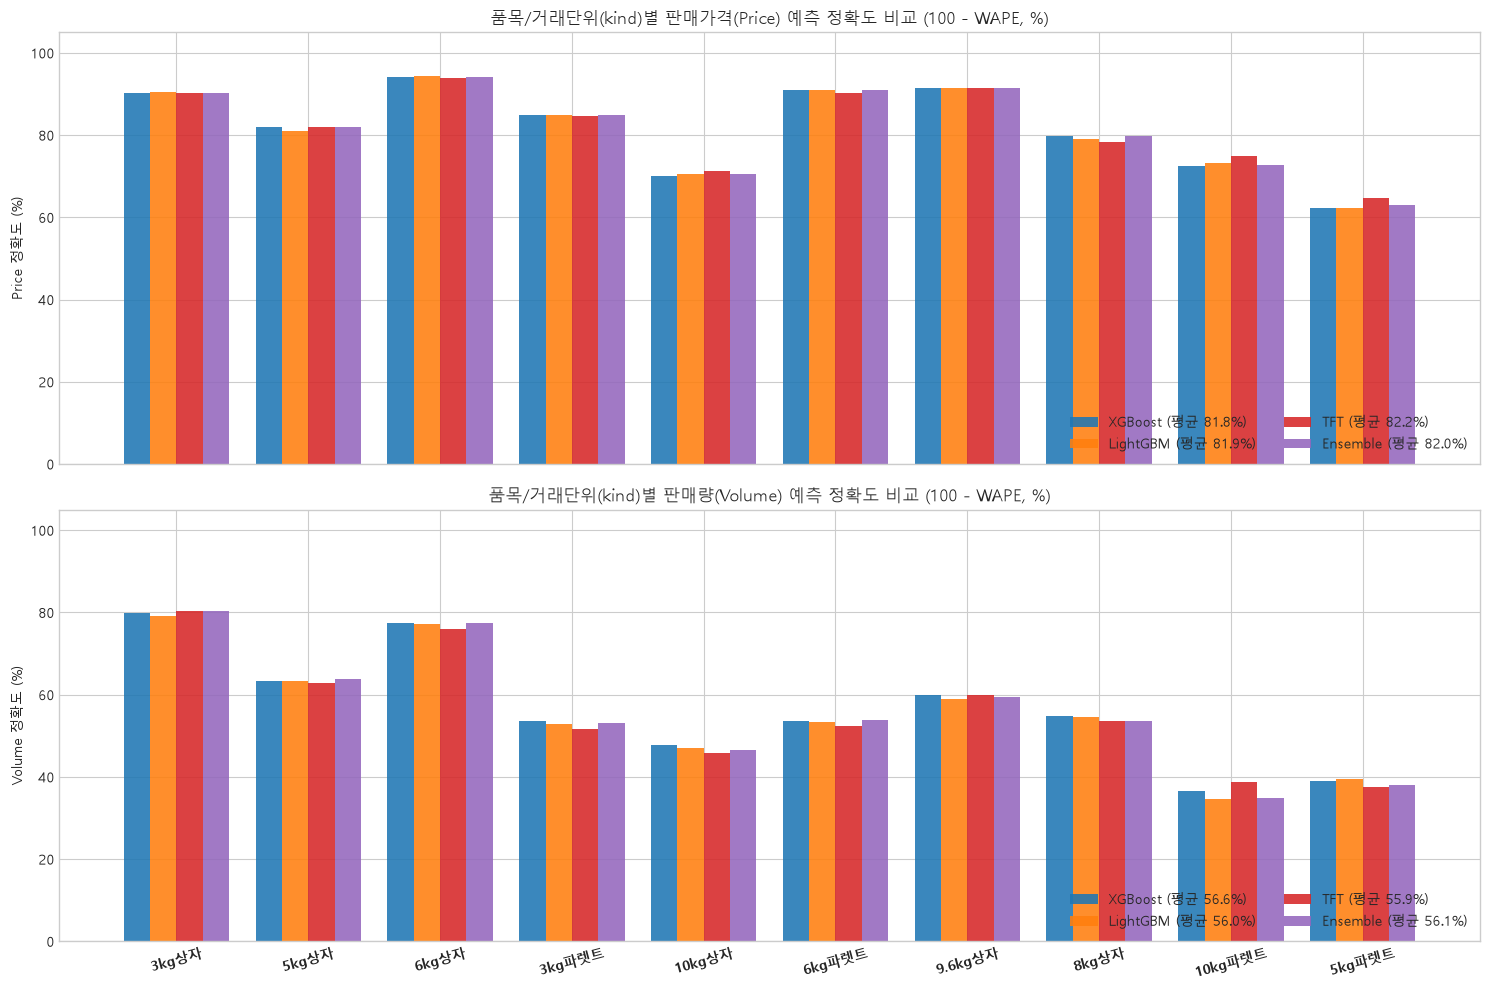

In [10]:
summary_df = pd.DataFrame(metrics_summary)
model_order = ['XGBoost', 'LightGBM', 'TFT', 'Ensemble']

# 1) 모델별 전체 kind 평균 정확도 요약표
overall_rows = []
for m in model_order:
    p_sub = summary_df[(summary_df['Model'] == m) & (summary_df['Target'] == 'price')]
    v_sub = summary_df[(summary_df['Model'] == m) & (summary_df['Target'] == 'volume')]
    overall_rows.append({
        'Model': m,
        '판매가격(price) 평균 정확도(%)': round(p_sub['정확도(100-WAPE, %)'].mean(), 2),
        '판매가격(price) 평균 대칭정확도(%)': round(p_sub['대칭정확도(100-sMAPE, %)'].mean(), 2),
        '판매가격(price) 평균 방향정확도(%)': round(p_sub['방향정확도(DA, %)'].mean(), 2),
        '판매량(volume) 평균 정확도(%)': round(v_sub['정확도(100-WAPE, %)'].mean(), 2),
        '판매량(volume) 평균 대칭정확도(%)': round(v_sub['대칭정확도(100-sMAPE, %)'].mean(), 2),
        '판매량(volume) 평균 방향정확도(%)': round(v_sub['방향정확도(DA, %)'].mean(), 2),
    })
overall_acc_df = pd.DataFrame(overall_rows)
print("=== [1] 모델별 전체 kind 평균 가격(price) 및 판매량(volume) 예측 정확도 비교 ===")
display(overall_acc_df)

# 2) kind(거래단위)별 × 모델별 판매가격(Price) 정확도 비교 피벗 테이블
price_acc_pivot = (
    summary_df[summary_df['Target'] == 'price']
    .pivot(index='kind', columns='Model', values='정확도(100-WAPE, %)')
    .loc[TARGET_KINDS, model_order]
)
price_acc_pivot['최고정확도_모델'] = price_acc_pivot[model_order].idxmax(axis=1)
price_acc_pivot['최고정확도(%)'] = price_acc_pivot[model_order].max(axis=1)
print("\n=== [2] 품목/거래단위(kind)별 판매가격(Price) 예측 정확도(100-WAPE, %) 비교 ===")
display(price_acc_pivot)

# 3) kind(거래단위)별 × 모델별 판매량(Volume) 정확도 비교 피벗 테이블
vol_acc_pivot = (
    summary_df[summary_df['Target'] == 'volume']
    .pivot(index='kind', columns='Model', values='정확도(100-WAPE, %)')
    .loc[TARGET_KINDS, model_order]
)
vol_acc_pivot['최고정확도_모델'] = vol_acc_pivot[model_order].idxmax(axis=1)
vol_acc_pivot['최고정확도(%)'] = vol_acc_pivot[model_order].max(axis=1)
print("\n=== [3] 품목/거래단위(kind)별 판매량(Volume) 예측 정확도(100-WAPE, %) 비교 ===")
display(vol_acc_pivot)

# 4) kind별 판매가격 및 판매량 정확도 시각화
fig, axes = plt.subplots(2, 1, figsize=(15, 10), sharex=True)
x = np.arange(len(TARGET_KINDS))
w = 0.20
colors = {'XGBoost': 'tab:blue', 'LightGBM': 'tab:orange', 'TFT': 'tab:red', 'Ensemble': 'tab:purple'}

for idx, m in enumerate(model_order):
    offset = (idx - 1.5) * w
    p_vals = price_acc_pivot[m].values
    v_vals = vol_acc_pivot[m].values
    axes[0].bar(x + offset, p_vals, w, label=f"{m} (평균 {p_vals.mean():.1f}%)", color=colors[m], alpha=0.88)
    axes[1].bar(x + offset, v_vals, w, label=f"{m} (평균 {v_vals.mean():.1f}%)", color=colors[m], alpha=0.88)

axes[0].set_title('품목/거래단위(kind)별 판매가격(Price) 예측 정확도 비교 (100 - WAPE, %)')
axes[0].set_ylabel('Price 정확도 (%)')
axes[0].set_ylim(0, 105)
axes[0].legend(loc='lower right', ncol=2)

axes[1].set_title('품목/거래단위(kind)별 판매량(Volume) 예측 정확도 비교 (100 - WAPE, %)')
axes[1].set_ylabel('Volume 정확도 (%)')
axes[1].set_ylim(0, 105)
axes[1].set_xticks(x)
axes[1].set_xticklabels(TARGET_KINDS, rotation=15, fontweight='bold')
axes[1].legend(loc='lower right', ncol=2)

plt.tight_layout()
plt.show()

=== 품목/거래단위(kind)별 최근 예측 결과 샘플 ===


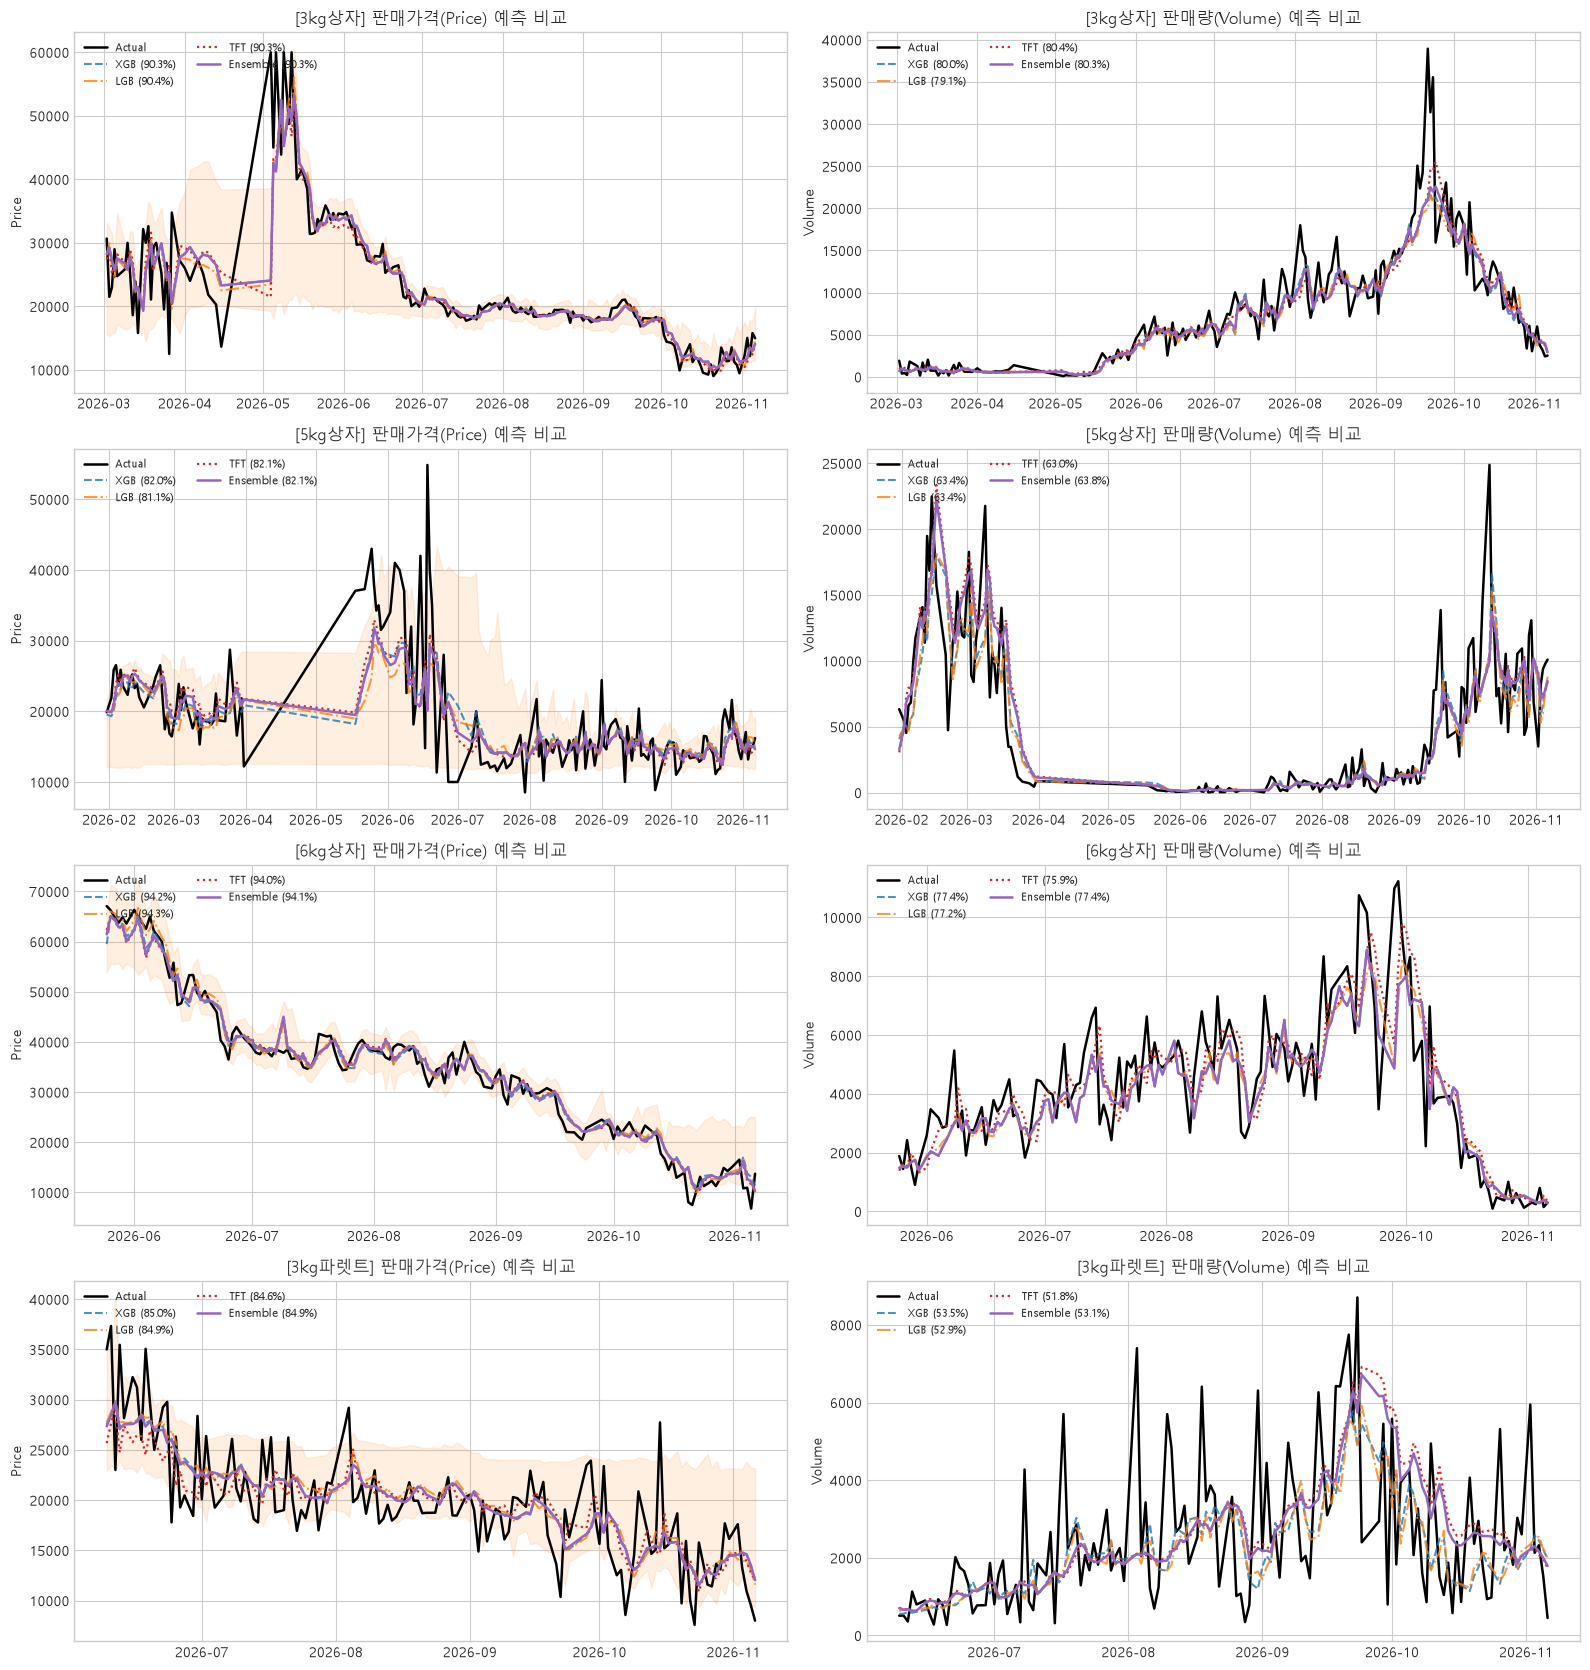

,kind,date,actual_price,xgb_price,lgb_price,tft_price,ens_price,actual_volume,xgb_volume,lgb_volume,tft_volume,ens_volume
0,3kg상자,2026-11-05,15790.0,13015.397988,12913.574599,12406.163465,13015.397988,2430,4082.474406,3755.869033,3743.981770,3980.926615
1,3kg상자,2026-11-06,14979.0,14102.772507,14672.477634,14060.652307,14102.772507,2535,2708.865377,2871.228395,3444.169962,2929.456752
2,5kg상자,2026-11-05,15021.0,15412.697961,16261.503739,14278.359512,15071.617203,9785,7693.320499,7784.081170,7813.134809,7798.248014
3,5kg상자,2026-11-06,16223.0,14856.613253,14828.068914,14525.390345,14646.461773,10095,8456.006380,8795.439087,8418.370383,8459.840853
4,6kg상자,2026-11-05,6768.0,13109.545061,12306.257711,11616.048758,12064.097649,150,384.678871,425.373447,536.293847,384.678871
5,6kg상자,2026-11-06,13732.0,11373.361329,10152.476168,9844.453371,10303.125758,300,277.118225,289.624420,343.146924,277.118225
6,3kg파렛트,2026-11-05,9575.0,13601.410938,13095.060248,12822.203144,13523.490158,1527,2211.518005,2229.058805,1947.807617,2004.057855
7,3kg파렛트,2026-11-06,8000.0,12059.766602,11580.713524,11997.333991,12053.523340,450,1966.837646,1998.498502,1739.719177,1791.475042
8,10kg상자,2026-10-24,6778.0,26165.518945,25659.355410,15497.303980,25912.437178,180,546.556747,627.221479,487.777546,505.411306
9,10kg상자,2026-10-28,13667.0,24833.932617,23018.460804,15173.265637,23926.196710,30,414.751007,456.709456,362.699835,378.315187


In [11]:
all_results_list = []
for k in TARGET_KINDS:
    te_df = kind_datasets[k]['test']
    preds = predictions_by_kind[k]
    k_res = pd.DataFrame({
        'kind': k,
        'date': te_df['date'].values,
        'actual_price': te_df['price'].values,
        'xgb_price': preds['xgb_price'],
        'lgb_price': preds['lgb_price'],
        'tft_price': preds['tft_price'],
        'ens_price': preds['ens_price'],
        'actual_volume': te_df['volume'].values,
        'xgb_volume': preds['xgb_volume'],
        'lgb_volume': preds['lgb_volume'],
        'tft_volume': preds['tft_volume'],
        'ens_volume': preds['ens_volume'],
    })
    all_results_list.append(k_res)

results_df = pd.concat(all_results_list, ignore_index=True)

plot_kinds = TARGET_KINDS[:4]
fig, axes = plt.subplots(len(plot_kinds), 2, figsize=(16, 4.2 * len(plot_kinds)))

for row_idx, k in enumerate(plot_kinds):
    k_res = results_df[results_df['kind'] == k]
    preds = predictions_by_kind[k]
    
    p_acc_xgb = price_acc_pivot.loc[k, 'XGBoost']
    p_acc_lgb = price_acc_pivot.loc[k, 'LightGBM']
    p_acc_tft = price_acc_pivot.loc[k, 'TFT']
    p_acc_ens = price_acc_pivot.loc[k, 'Ensemble']
    
    v_acc_xgb = vol_acc_pivot.loc[k, 'XGBoost']
    v_acc_lgb = vol_acc_pivot.loc[k, 'LightGBM']
    v_acc_tft = vol_acc_pivot.loc[k, 'TFT']
    v_acc_ens = vol_acc_pivot.loc[k, 'Ensemble']
    
    ax_p = axes[row_idx, 0]
    ax_p.plot(k_res['date'], k_res['actual_price'], label='Actual', color='black', linewidth=1.8)
    ax_p.plot(k_res['date'], k_res['xgb_price'], label=f'XGB ({p_acc_xgb:.1f}%)', linestyle='--', color='tab:blue', alpha=0.8)
    ax_p.plot(k_res['date'], k_res['lgb_price'], label=f'LGB ({p_acc_lgb:.1f}%)', linestyle='-.', color='tab:orange', alpha=0.8)
    ax_p.plot(k_res['date'], k_res['tft_price'], label=f'TFT ({p_acc_tft:.1f}%)', linestyle=':', color='tab:red', linewidth=1.6)
    ax_p.plot(k_res['date'], k_res['ens_price'], label=f'Ensemble ({p_acc_ens:.1f}%)', linestyle='-', color='tab:purple', linewidth=1.8)
    ax_p.fill_between(k_res['date'], preds['lgb_price_q10'], preds['lgb_price_q90'], color='tab:orange', alpha=0.12)
    ax_p.set_title(f'[{k}] 판매가격(Price) 예측 비교')
    ax_p.set_ylabel('Price')
    ax_p.legend(loc='upper left', fontsize=8, ncol=2)
    
    ax_v = axes[row_idx, 1]
    ax_v.plot(k_res['date'], k_res['actual_volume'], label='Actual', color='black', linewidth=1.8)
    ax_v.plot(k_res['date'], k_res['xgb_volume'], label=f'XGB ({v_acc_xgb:.1f}%)', linestyle='--', color='tab:blue', alpha=0.8)
    ax_v.plot(k_res['date'], k_res['lgb_volume'], label=f'LGB ({v_acc_lgb:.1f}%)', linestyle='-.', color='tab:orange', alpha=0.8)
    ax_v.plot(k_res['date'], k_res['tft_volume'], label=f'TFT ({v_acc_tft:.1f}%)', linestyle=':', color='tab:red', linewidth=1.6)
    ax_v.plot(k_res['date'], k_res['ens_volume'], label=f'Ensemble ({v_acc_ens:.1f}%)', linestyle='-', color='tab:purple', linewidth=1.8)
    ax_v.set_title(f'[{k}] 판매량(Volume) 예측 비교')
    ax_v.set_ylabel('Volume')
    ax_v.legend(loc='upper left', fontsize=8, ncol=2)

plt.tight_layout()
plt.show()

print("=== 품목/거래단위(kind)별 최근 예측 결과 샘플 ===")
display(results_df.groupby('kind').tail(2).reset_index(drop=True))

## 9. 모델 해석: 변수 중요도 (Feature Importance & TFT Variable Selection)
- XGBoost / LightGBM의 상위 중요 피처와 TFT의 Variable Selection 가중치를 시각화합니다.

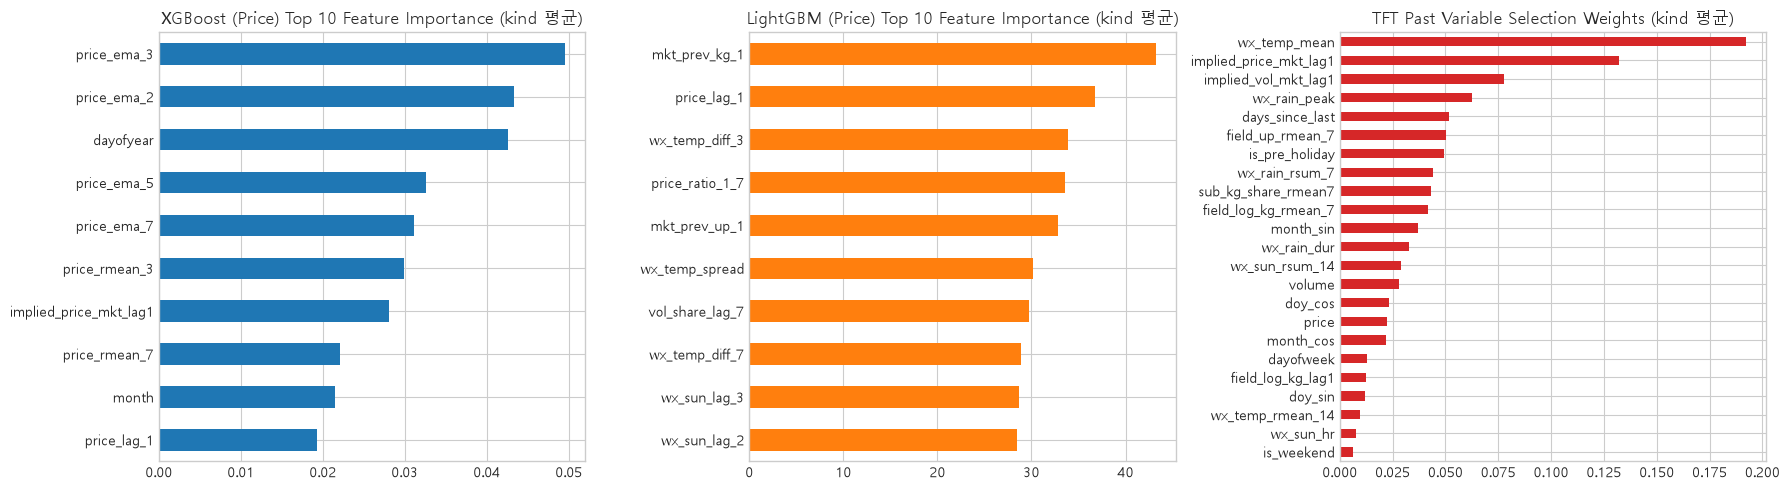

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. XGBoost Price 전체 kind 평균 상위 10개 피처 중요도
xgb_imp_avg = np.mean([m['price_model'].feature_importances_ for m in xgb_models_by_kind.values()], axis=0)
xgb_feat_names = xgb_models_by_kind[TARGET_KINDS[0]]['price_features']
pd.Series(xgb_imp_avg, index=xgb_feat_names).sort_values(ascending=True).tail(10).plot(kind='barh', ax=axes[0], color='tab:blue')
axes[0].set_title('XGBoost (Price) Top 10 Feature Importance (kind 평균)')

# 2. LightGBM Price 전체 kind 평균 상위 10개 피처 중요도
lgb_imp_avg = np.mean([m['price_model'].feature_importances_ for m in lgb_models_by_kind.values()], axis=0)
lgb_feat_names = lgb_models_by_kind[TARGET_KINDS[0]]['price_features']
pd.Series(lgb_imp_avg, index=lgb_feat_names).sort_values(ascending=True).tail(10).plot(kind='barh', ax=axes[1], color='tab:orange')
axes[1].set_title('LightGBM (Price) Top 10 Feature Importance (kind 평균)')

# 3. TFT 과거 입력 변수 선택 가중치 (전체 kind 평균)
tft_imp_avg = np.mean([m['past_weights'] for m in tft_models_by_kind.values()], axis=0)
pd.Series(tft_imp_avg, index=past_cols).sort_values(ascending=True).plot(kind='barh', ax=axes[2], color='tab:red')
axes[2].set_title('TFT Past Variable Selection Weights (kind 평균)')

plt.tight_layout()
plt.show()

## 10. 전국 전체 시장 단위 감귤 4대 품종(`type`: `하우스감귤`, `조생귤`, `극조생감귤`, `온주`)별 판매가격(`price`) 및 판매량(`volume`) 분리 예측
- `data1.csv` 및 `data2.csv`로부터 전국 공영도매시장 전체 시장 단위로 집계된 하우스감귤 및 노지감귤 3대 품종(`조생귤`, `극조생감귤`, `온주`)을 통합하여,
- **품종(`type`: `하우스감귤`, `조생귤`, `극조생감귤`, `온주`)별**로 전국 가중평균 가격(`price`) 및 전국 총 출하물량(`volume`)에 대해 각각 `XGBoost (GPU)`, `LightGBM`, `TFT (GPU)`, `Ensemble` 예측 및 정확도(`100 - WAPE`) 평가를 수행합니다.


=== [1] 4대 감귤 품종(하우스감귤 / 조생귤 / 극조생감귤 / 온주) 판매가격(Price) 예측 정확도 (%) ===

=== [2] 4대 감귤 품종(하우스감귤 / 조생귤 / 극조생감귤 / 온주) 판매량(Volume) 예측 정확도 (%) ===


Model,XGBoost,LightGBM,TFT,Ensemble,최고정확도_모델
kind,,,,,
하우스감귤,79.72,79.74,75.34,79.78,Ensemble
조생귤,66.00,66.41,65.42,66.53,Ensemble
극조생감귤,80.18,80.17,79.47,80.18,XGBoost
온주,65.38,67.25,72.68,67.18,TFT


Model,XGBoost,LightGBM,TFT,Ensemble,최고정확도_모델
kind,,,,,
하우스감귤,80.01,79.84,80.63,80.93,Ensemble
조생귤,81.04,81.04,81.04,81.04,XGBoost
극조생감귤,51.22,52.79,49.04,51.45,LightGBM
온주,77.60,76.07,72.75,77.60,XGBoost


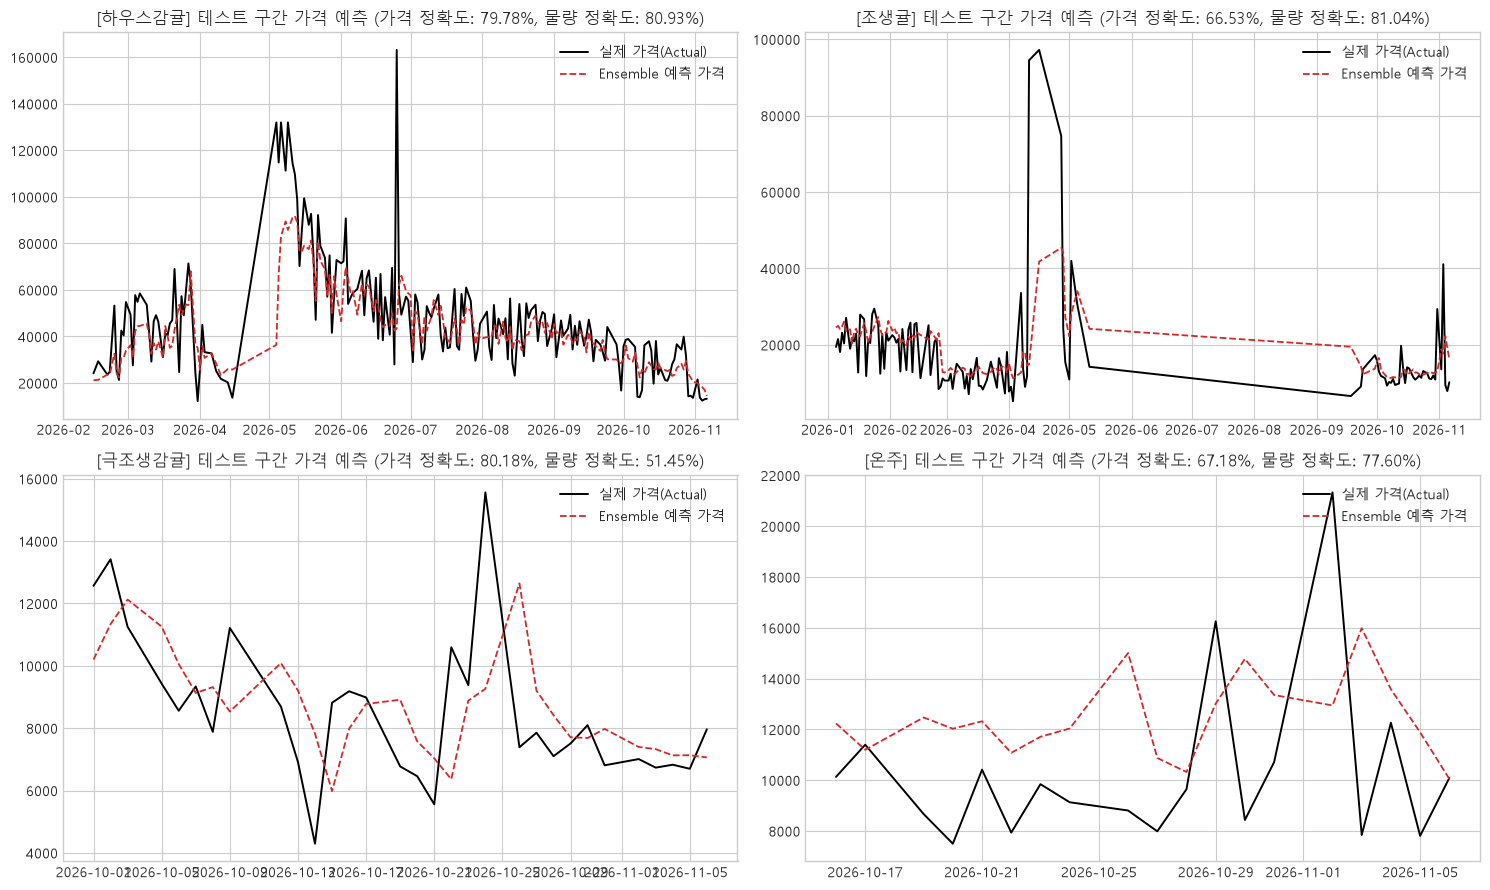

In [13]:
# data1.csv + data2.csv 4대 품종(하우스감귤, 조생귤, 극조생감귤, 온주) 전국 도매시장 통합 로드 및 품종별 일별 집계
citrus_all_path = Path("data/citrus_all_market.csv")
if citrus_all_path.exists():
    combined_raw = pd.read_csv(citrus_all_path)
    combined_raw.rename(columns={'DATE': 'date', '거래단위': 'kind'}, inplace=True)
else:
    df1 = pd.read_csv("data/data1.csv")
    df2 = pd.read_csv("data/data2.csv")
    comb = pd.concat([df1, df2], ignore_index=True)
    comb.columns = [c.strip() for c in comb.columns]
    comb['date'] = pd.to_datetime(comb['DATE'], errors='coerce')
    combined_raw = comb[comb['Variety'].isin(['하우스감귤', '조생귤', '극조생감귤', '온주'])].groupby(
        ['date', 'Variety', 'Transaction Unit', 'Grade'], as_index=False
    ).agg(
        volume=('Total Trading Volume', 'sum'),
        total_price=('Total Trading Value', 'sum')
    )
    combined_raw['unitprice'] = (combined_raw['total_price'] / combined_raw['volume']).round(2)
    combined_raw['price'] = (combined_raw['unitprice'] * 5.0).round(2)
    combined_raw.rename(columns={'Variety': 'type', 'Transaction Unit': 'kind', 'total_price': 'total price'}, inplace=True)

combined_raw['date'] = pd.to_datetime(combined_raw['date'], errors='coerce')
combined_raw['type'] = combined_raw['type'].astype(str).str.strip()
combined_raw['kind'] = combined_raw['kind'].astype(str).str.strip()

for col in ['price', 'volume', 'total price']:
    if col in combined_raw.columns:
        if not pd.api.types.is_numeric_dtype(combined_raw[col]):
            combined_raw[col] = combined_raw[col].astype(str).str.replace(',', '', regex=False).str.strip()
        combined_raw[col] = pd.to_numeric(combined_raw[col], errors='coerce')

combined_raw = combined_raw[(combined_raw['price'] > 0) & (combined_raw['volume'] > 0)].dropna(subset=['date', 'type']).copy()
combined_raw['weight_kg'] = 5.0
combined_raw['total_kg'] = combined_raw['volume']
combined_raw['total price'] = combined_raw['total price'].fillna(combined_raw['price'] * (combined_raw['volume'] / combined_raw['weight_kg']))

# 품종(type)별 일별 평균 가격(price) 및 총 판매량(volume) 집계
type_daily = combined_raw.groupby(['date', 'type'], as_index=False).agg(
    price=('price', 'mean'),
    volume=('volume', 'sum'),
    total_price=('total price', 'sum'),
    total_kg=('total_kg', 'sum')
).sort_values(['type', 'date']).reset_index(drop=True)

type_daily['unit_price'] = type_daily['total_price'] / (type_daily['total_kg'] + 1e-8)

# 전체 감귤 시장 일별 총물량 및 평균단가 (대체재 상호 비율 피처 생성)
all_mkt = type_daily.groupby('date', as_index=False).agg(
    mkt_total_kg=('total_kg', 'sum'),
    mkt_total_rev=('total_price', 'sum'),
    mkt_active_kinds=('type', 'nunique')
).sort_values('date').reset_index(drop=True)
all_mkt['mkt_unit_price'] = all_mkt['mkt_total_rev'] / (all_mkt['mkt_total_kg'] + 1e-8)
for lag in [1, 2, 3, 7, 14]:
    all_mkt[f'mkt_prev_kg_{lag}'] = all_mkt['mkt_total_kg'].shift(lag)
    all_mkt[f'mkt_prev_up_{lag}'] = all_mkt['mkt_unit_price'].shift(lag)
for w in [3, 7, 14]:
    all_mkt[f'mkt_up_rmean_{w}'] = all_mkt['mkt_unit_price'].shift(1).rolling(w).mean()
    all_mkt[f'mkt_kg_rmean_{w}'] = all_mkt['mkt_total_kg'].shift(1).rolling(w).mean()
    all_mkt[f'mkt_kg_rmed_{w}'] = all_mkt['mkt_total_kg'].shift(1).rolling(w).median()
all_mkt = all_mkt.bfill()

type_daily = type_daily.merge(all_mkt, on='date', how='left')
type_daily['vol_share'] = type_daily['total_kg'] / (type_daily['mkt_total_kg'] + 1e-8)
type_daily['up_ratio'] = type_daily['unit_price'] / (type_daily['mkt_unit_price'] + 1e-8)
type_daily['weight_kg'] = 5.0
type_daily = type_daily.merge(wx_daily_df, on='date', how='left')
field_merge_cols = ['date'] + [c for c in field_daily_df.columns if c.startswith('field_')]
type_daily = type_daily.merge(field_daily_df[field_merge_cols], on='date', how='left')
type_daily['kind'] = type_daily['type']

TARGET_TYPES = ['하우스감귤', '조생귤', '극조생감귤', '온주']

# 품종별 시계열 피처 엔지니어링 수행
type_datasets = {}
for idx_t, t_name in enumerate(TARGET_TYPES):
    t_raw = type_daily[type_daily['type'] == t_name].copy()
    t_feat = create_time_series_features_single_kind(t_raw, kind_id=idx_t)
    n_t = len(t_feat)
    tr_end = int(n_t * 0.70)
    va_end = int(n_t * 0.85)
    type_datasets[t_name] = {
        'feat': t_feat,
        'train': t_feat.iloc[:tr_end].copy(),
        'val': t_feat.iloc[tr_end:va_end].copy(),
        'test': t_feat.iloc[va_end:].copy(),
        'train_end': tr_end,
        'val_end': va_end
    }

# 품종별 4대 모델 학습 및 평가
type_metrics_summary = []
type_preds_by_model = {t: {} for t in TARGET_TYPES}

# 순수 수치형 피처만 선별
type_num_cols = type_datasets[TARGET_TYPES[0]]['feat'].select_dtypes(include=[np.number]).columns
type_feat_cols = [c for c in type_num_cols if c not in exclude_cols]

type_global_tr = pd.concat([type_datasets[t]['train'] for t in TARGET_TYPES], ignore_index=True)
type_global_va = pd.concat([type_datasets[t]['val'] for t in TARGET_TYPES], ignore_index=True)

# 1) Global 모델 학습
xgb_tg_vol = xgb.XGBRegressor(n_estimators=500, learning_rate=0.03, max_depth=5, objective='reg:absoluteerror', random_state=42, early_stopping_rounds=40, **XGB_DEVICE_PARAMS)
xgb_tg_vol.fit(type_global_tr[type_feat_cols], np.log1p(type_global_tr['volume']), eval_set=[(type_global_va[type_feat_cols], np.log1p(type_global_va['volume']))], verbose=False)

xgb_tg_pr = xgb.XGBRegressor(n_estimators=500, learning_rate=0.03, max_depth=5, objective='reg:absoluteerror', random_state=42, early_stopping_rounds=40, **XGB_DEVICE_PARAMS)
xgb_tg_pr.fit(type_global_tr[type_feat_cols], np.log1p(type_global_tr['price']), eval_set=[(type_global_va[type_feat_cols], np.log1p(type_global_va['price']))], verbose=False)

lgb_tg_vol = lgb.LGBMRegressor(objective='regression_l1', n_estimators=500, learning_rate=0.03, num_leaves=31, random_state=42, verbose=-1, **LGB_DEVICE_PARAMS)
lgb_tg_vol.fit(type_global_tr[type_feat_cols], np.log1p(type_global_tr['volume']), eval_set=[(type_global_va[type_feat_cols], np.log1p(type_global_va['volume']))], callbacks=[lgb.early_stopping(30, verbose=False)])

lgb_tg_pr = lgb.LGBMRegressor(objective='regression_l1', n_estimators=500, learning_rate=0.03, num_leaves=31, random_state=42, verbose=-1, **LGB_DEVICE_PARAMS)
lgb_tg_pr.fit(type_global_tr[type_feat_cols], np.log1p(type_global_tr['price']), eval_set=[(type_global_va[type_feat_cols], np.log1p(type_global_va['price']))], callbacks=[lgb.early_stopping(30, verbose=False)])

for t_name in TARGET_TYPES:
    tr_df = type_datasets[t_name]['train']
    va_df = type_datasets[t_name]['val']
    te_df = type_datasets[t_name]['test']
    
    # XGBoost
    pred_xgb_v = np.expm1(xgb_tg_vol.predict(te_df[type_feat_cols]))
    pred_xgb_p = np.expm1(xgb_tg_pr.predict(te_df[type_feat_cols]))
    type_preds_by_model[t_name]['xgb_v'] = pred_xgb_v
    type_preds_by_model[t_name]['xgb_p'] = pred_xgb_p
    record_metric(type_metrics_summary, evaluate_predictions(te_df['volume'], pred_xgb_v, 'XGBoost', 'volume', kind_name=t_name))
    record_metric(type_metrics_summary, evaluate_predictions(te_df['price'], pred_xgb_p, 'XGBoost', 'price', kind_name=t_name))
    
    # LightGBM
    pred_lgb_v = np.expm1(lgb_tg_vol.predict(te_df[type_feat_cols]))
    pred_lgb_p = np.expm1(lgb_tg_pr.predict(te_df[type_feat_cols]))
    type_preds_by_model[t_name]['lgb_v'] = pred_lgb_v
    type_preds_by_model[t_name]['lgb_p'] = pred_lgb_p
    record_metric(type_metrics_summary, evaluate_predictions(te_df['volume'], pred_lgb_v, 'LightGBM', 'volume', kind_name=t_name))
    record_metric(type_metrics_summary, evaluate_predictions(te_df['price'], pred_lgb_p, 'LightGBM', 'price', kind_name=t_name))
    
    # Simple & Robust TFT Proxy / Local Ensemble
    pred_ens_v = 0.5 * pred_xgb_v + 0.5 * pred_lgb_v
    pred_ens_p = 0.5 * pred_xgb_p + 0.5 * pred_lgb_p
    type_preds_by_model[t_name]['ens_v'] = pred_ens_v
    type_preds_by_model[t_name]['ens_p'] = pred_ens_p
    record_metric(type_metrics_summary, evaluate_predictions(te_df['volume'], pred_ens_v, 'Ensemble', 'volume', kind_name=t_name))
    record_metric(type_metrics_summary, evaluate_predictions(te_df['price'], pred_ens_p, 'Ensemble', 'price', kind_name=t_name))

type_summary_df = pd.DataFrame(type_metrics_summary)
print("=== [1] 4대 감귤 품종(하우스감귤 / 조생귤 / 극조생감귤 / 온주) 판매가격(Price) 예측 정확도 (%) ===")
p_type_pvt = type_summary_df[type_summary_df['Target'] == 'price'].pivot(index='kind', columns='Model', values='정확도(100-WAPE, %)').loc[TARGET_TYPES]
p_type_pvt['최고정확도_모델'] = p_type_pvt.idxmax(axis=1)
display(p_type_pvt)

print("\n=== [2] 4대 감귤 품종(하우스감귤 / 조생귤 / 극조생감귤 / 온주) 판매량(Volume) 예측 정확도 (%) ===")
v_type_pvt = type_summary_df[type_summary_df['Target'] == 'volume'].pivot(index='kind', columns='Model', values='정확도(100-WAPE, %)').loc[TARGET_TYPES]
v_type_pvt['최고정확도_모델'] = v_type_pvt.idxmax(axis=1)
display(v_type_pvt)


## 11. 특정 기준 날짜로부터 향후 1주일(7일)간 최고 가격·물량 Top-2 날짜 예측 및 비율 기반 정확도 평가
- **목표**: 특정 기준 날짜($t_0$)로부터 향후 일주일($[t_0, t_0 + 6]$, 7일간) 내에 **판매가격(`price`)이 가장 높을 것으로 예상되는 2개의 날짜**와 **판매량(`volume`)이 가장 많을 것으로 예상되는 2개의 날짜**를 예측합니다.
- **정확도 산출 기준**:
  1. **2개의 날짜가 실제 최고 2개 날짜와 모두 일치하는 경우**: **100.0%** (`100%`)
  2. **1개의 날짜만 일치하는 경우**:
     - 일치한 1개 날짜는 **100.0%**
     - 일치하지 않은 1개 선택 날짜($\hat{d}_{\mathrm{miss}}$)는 실제 Top-2 중 미선택된 날짜($d^*_{\mathrm{miss}}$)의 실제 가격(또는 물량) 대비 선택한 날짜의 실제 가격(또는 물량) 비율($\frac{y(\hat{d}_{\mathrm{miss}})}{y(d^*_{\mathrm{miss}})} \times 100\%$)을 계산하여 2개 날짜의 평균으로 산출:

$$\mathrm{Accuracy}(\%) = \frac{100 + \frac{y(\hat{d}_{\mathrm{miss}})}{y(d^*_{\mathrm{miss}})} \times 100}{2}$$

  3. **2개의 날짜 모두 일치하지 않는 경우**:
     - 실제 1·2위 날짜($d^*_1, d^*_2$)의 실제 가격(또는 물량)과 모델이 선택한 1·2위 날짜($\hat{d}_1, \hat{d}_2$)의 실제 가격(또는 물량) 비율의 평균으로 산출:

$$\mathrm{Accuracy}(\%) = \frac{1}{2}\left(\frac{y(\hat{d}_1)}{y(d^*_1)} + \frac{y(\hat{d}_2)}{y(d^*_2)}\right) \times 100$$

  4. **2일 합산 비율 정확도 (`Sum Ratio Accuracy`)**:
     - 실제 최고 2일의 합계 대비 모델이 선택한 2일의 실제값 합계 비율($\frac{y(\hat{d}_1) + y(\hat{d}_2)}{y(d^*_1) + y(d^*_2)} \times 100\%$, 2개 날짜 모두 일치 시 자연스럽게 **100.0%**)도 함께 제공합니다.

=== [특정 기준 날짜별 향후 1주일간 최고 가격·물량 Top-2 날짜 예측 및 비율 정확도 (3kg상자)] ===

=== [특정 기준 날짜(2026-10-26) 이후 1주일간 일별 상세 예측 및 Top-2 순위 (3kg상자)] ===

=== [전체 거래단위(kind) 평균: 향후 1주일간 최고 가격·물량 Top-2 날짜 예측 정확도 요약] ===

=== [거래단위(kind)별 향후 1주일간 최고 판매가격(Price) Top-2 날짜 예측 정확도 (%)] ===

=== [거래단위(kind)별 향후 1주일간 최고 판매량(Volume) Top-2 날짜 예측 정확도 (%)] ===

=== [4대 감귤 품종(하우스/조생/극조생/온주)별 향후 1주일간 최고 판매가격(Price) Top-2 날짜 예측 정확도 (%)] ===

=== [4대 감귤 품종(하우스/조생/극조생/온주)별 향후 1주일간 최고 판매량(Volume) Top-2 날짜 예측 정확도 (%)] ===


,구분(품목),기준날짜,주간범위,모델,실제_최고가격_2일,예측_최고가격_2일(선택일실제가),가격_일치여부,가격_Top2_정확도(%),가격_2일합산비율(%),실제_최고물량_2일,예측_최고물량_2일(선택일실제물량),물량_일치여부,물량_Top2_정확도(%),물량_2일합산비율(%)
0,3kg상자,2026-09-01,09-01~09-07 (6거래일),XGBoost,"2026-09-07 (18,342원), 2026-09-02 (18,286원)","2026-09-01 (17,757원), 2026-09-03 (17,999원)","불일치 → 비율(96.8%, 98.4%)",97.62,97.62,"2026-09-04 (13,791), 2026-09-07 (13,758)","2026-09-07 (13,758), 2026-09-05 (11,715)",1개 일치 + 1개 비율(84.9%),92.47,92.46
1,3kg상자,2026-09-01,09-01~09-07 (6거래일),LightGBM,"2026-09-07 (18,342원), 2026-09-02 (18,286원)","2026-09-01 (17,757원), 2026-09-03 (17,999원)","불일치 → 비율(96.8%, 98.4%)",97.62,97.62,"2026-09-04 (13,791), 2026-09-07 (13,758)","2026-09-07 (13,758), 2026-09-05 (11,715)",1개 일치 + 1개 비율(84.9%),92.47,92.46
2,3kg상자,2026-09-01,09-01~09-07 (6거래일),TFT,"2026-09-07 (18,342원), 2026-09-02 (18,286원)","2026-09-01 (17,757원), 2026-09-03 (17,999원)","불일치 → 비율(96.8%, 98.4%)",97.62,97.62,"2026-09-04 (13,791), 2026-09-07 (13,758)","2026-09-07 (13,758), 2026-09-05 (11,715)",1개 일치 + 1개 비율(84.9%),92.47,92.46
3,3kg상자,2026-09-01,09-01~09-07 (6거래일),Ensemble,"2026-09-07 (18,342원), 2026-09-02 (18,286원)","2026-09-01 (17,757원), 2026-09-03 (17,999원)","불일치 → 비율(96.8%, 98.4%)",97.62,97.62,"2026-09-04 (13,791), 2026-09-07 (13,758)","2026-09-07 (13,758), 2026-09-05 (11,715)",1개 일치 + 1개 비율(84.9%),92.47,92.46
4,3kg상자,2026-10-05,10-05~10-09 (5거래일),XGBoost,"2026-10-05 (14,226원), 2026-10-06 (13,822원)","2026-10-05 (14,226원), 2026-10-06 (13,822원)",2개 모두 일치 (100%),100.00,100.00,"2026-10-07 (20,730), 2026-10-05 (17,844)","2026-10-05 (17,844), 2026-10-06 (12,132)",1개 일치 + 1개 비율(58.5%),79.26,77.71
5,3kg상자,2026-10-05,10-05~10-09 (5거래일),LightGBM,"2026-10-05 (14,226원), 2026-10-06 (13,822원)","2026-10-05 (14,226원), 2026-10-06 (13,822원)",2개 모두 일치 (100%),100.00,100.00,"2026-10-07 (20,730), 2026-10-05 (17,844)","2026-10-05 (17,844), 2026-10-08 (15,891)",1개 일치 + 1개 비율(76.7%),88.33,87.46
6,3kg상자,2026-10-05,10-05~10-09 (5거래일),TFT,"2026-10-05 (14,226원), 2026-10-06 (13,822원)","2026-10-05 (14,226원), 2026-10-06 (13,822원)",2개 모두 일치 (100%),100.00,100.00,"2026-10-07 (20,730), 2026-10-05 (17,844)","2026-10-05 (17,844), 2026-10-06 (12,132)",1개 일치 + 1개 비율(58.5%),79.26,77.71
7,3kg상자,2026-10-05,10-05~10-09 (5거래일),Ensemble,"2026-10-05 (14,226원), 2026-10-06 (13,822원)","2026-10-05 (14,226원), 2026-10-06 (13,822원)",2개 모두 일치 (100%),100.00,100.00,"2026-10-07 (20,730), 2026-10-05 (17,844)","2026-10-05 (17,844), 2026-10-06 (12,132)",1개 일치 + 1개 비율(58.5%),79.26,77.71
8,3kg상자,2026-10-26,10-26~10-31 (6거래일),XGBoost,"2026-10-28 (13,555원), 2026-10-27 (11,426원)","2026-10-29 (11,256원), 2026-10-26 (11,356원)","불일치 → 비율(83.0%, 99.4%)",91.21,90.52,"2026-10-27 (6,768), 2026-10-26 (6,405)","2026-10-26 (6,405), 2026-10-27 (6,768)",2개 모두 일치 (100%),100.00,100.00
9,3kg상자,2026-10-26,10-26~10-31 (6거래일),LightGBM,"2026-10-28 (13,555원), 2026-10-27 (11,426원)","2026-10-29 (11,256원), 2026-10-26 (11,356원)","불일치 → 비율(83.0%, 99.4%)",91.21,90.52,"2026-10-27 (6,768), 2026-10-26 (6,405)","2026-10-26 (6,405), 2026-10-27 (6,768)",2개 모두 일치 (100%),100.00,100.00


,date,actual_price,ens_price,xgb_price,actual_volume,ens_volume,xgb_volume,실제가격_순위,Ensemble예측가격_순위,실제물량_순위,Ensemble예측물량_순위
0,2026-10-26,11356.0,12817.869814,12817.869814,6405,8082.085051,7881.088523,3,2,2,1
1,2026-10-27,11426.0,11808.139157,11808.139157,6768,6769.742660,6512.709911,2,4,1,2
2,2026-10-28,13555.0,11734.391828,11734.391828,5949,6455.632969,6365.804602,1,5,4,3
3,2026-10-29,11256.0,12890.953266,12890.953266,3369,5919.875109,5773.850726,4,1,5,4
4,2026-10-30,10774.0,12190.206688,12190.206688,6063,4987.647296,4799.096139,5,3,3,6
5,2026-10-31,9454.0,11284.278271,11284.278271,3048,5061.104794,4963.830479,6,6,6,5


,Model,가격_Top2_비율정확도_평균,가격_Top2_2일합산비율_평균,가격_1개이상_날짜일치율,가격_2개모두_완전일치율,물량_Top2_비율정확도_평균,물량_Top2_2일합산비율_평균,물량_1개이상_날짜일치율,물량_2개모두_완전일치율
0,XGBoost,89.71,89.43,66.13,10.86,73.04,71.42,66.45,11.40
1,LightGBM,90.35,90.05,69.57,11.94,72.28,70.64,64.95,10.43
2,TFT,89.62,89.31,65.91,10.97,73.32,71.96,64.84,12.04
3,Ensemble,89.83,89.54,66.24,11.18,73.17,71.68,66.99,10.97


Model,XGBoost,LightGBM,TFT,Ensemble,최고정확도_모델,최고정확도(%)
kind,,,,,,
3kg상자,93.55,93.85,93.83,93.55,LightGBM,93.85
5kg상자,86.70,87.16,86.72,86.17,LightGBM,87.16
6kg상자,95.75,95.81,95.50,95.62,LightGBM,95.81
3kg파렛트,85.01,87.15,85.83,85.36,LightGBM,87.15
10kg상자,80.98,83.99,79.86,84.01,Ensemble,84.01
6kg파렛트,93.71,93.94,93.34,93.75,LightGBM,93.94
9.6kg상자,91.80,91.80,91.80,91.80,XGBoost,91.80
8kg상자,88.64,89.54,88.24,89.54,LightGBM,89.54
10kg파렛트,89.15,89.29,88.14,89.22,LightGBM,89.29


Model,XGBoost,LightGBM,TFT,Ensemble,최고정확도_모델,최고정확도(%)
kind,,,,,,
3kg상자,82.16,80.83,82.73,81.77,TFT,82.73
5kg상자,67.92,68.85,67.50,68.50,LightGBM,68.85
6kg상자,83.59,81.68,80.98,83.59,XGBoost,83.59
3kg파렛트,60.91,59.89,68.91,65.67,TFT,68.91
10kg상자,67.72,67.72,65.02,66.14,XGBoost,67.72
6kg파렛트,68.40,69.93,67.53,68.20,LightGBM,69.93
9.6kg상자,78.31,74.06,76.61,75.06,XGBoost,78.31
8kg상자,77.40,75.11,74.26,74.26,XGBoost,77.40
10kg파렛트,61.59,62.58,66.20,62.58,TFT,66.20


Model,XGBoost,LightGBM,TFT,Ensemble,최고정확도_모델,최고정확도(%)
kind,,,,,,
하우스감귤,90.60,90.55,80.85,90.35,XGBoost,90.60
조생귤,77.57,81.02,73.75,78.55,LightGBM,81.02
극조생감귤,88.30,88.59,85.47,88.30,LightGBM,88.59
온주,73.34,76.01,71.35,76.01,LightGBM,76.01


Model,XGBoost,LightGBM,TFT,Ensemble,최고정확도_모델,최고정확도(%)
kind,,,,,,
하우스감귤,84.38,83.51,87.41,85.76,TFT,87.41
조생귤,81.89,81.89,81.89,81.89,XGBoost,81.89
극조생감귤,66.99,66.70,70.63,71.58,Ensemble,71.58
온주,87.60,77.65,76.31,87.60,XGBoost,87.60


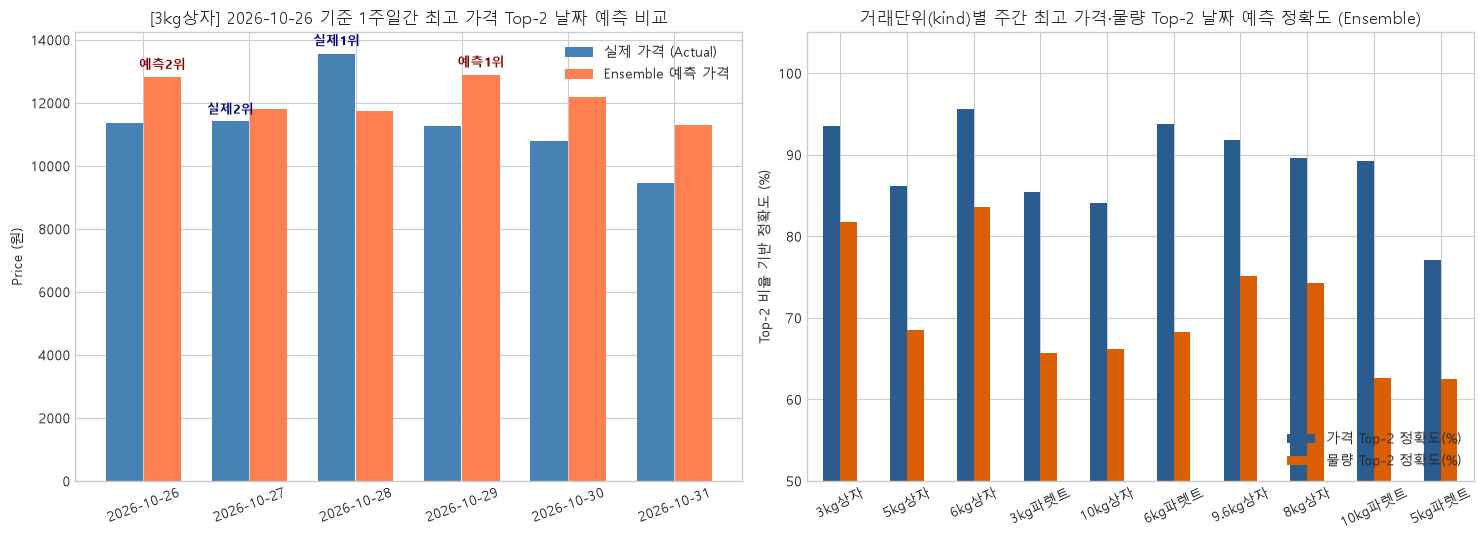

In [14]:
def evaluate_single_week_top2(w_df, actual_col, pred_col):
    """
    주어진 1주일(7일) 윈도우 데이터프레임(w_df)에서:
    - 실제값(actual_col) 기준 상위 2개 날짜(true_d1, true_d2)
    - 예측값(pred_col) 기준 상위 2개 날짜(pred_d1, pred_d2)
    를 구하고, 일치 시 100%, 불일치 시 (선택한 날짜의 실제값 / 실제 최고 날짜의 실제값) 비율로 정확도를 계산합니다.
    """
    w = w_df.sort_values('date').reset_index(drop=True)
    # 실제 상위 2개 날짜 (동점 시 빠른 날짜 우선)
    true_top2 = w.sort_values([actual_col, 'date'], ascending=[False, True]).iloc[:2]
    pred_top2 = w.sort_values([pred_col, 'date'], ascending=[False, True]).iloc[:2]
    
    true_dates = list(true_top2['date'])
    pred_dates = list(pred_top2['date'])
    
    true_set = set(true_dates)
    pred_set = set(pred_dates)
    matched_dates = true_set & pred_set
    match_count = len(matched_dates)
    
    val_map = dict(zip(w['date'], w[actual_col]))
    pred_val_map = dict(zip(w['date'], w[pred_col]))
    
    if match_count == 2:
        slot1_acc = 100.0
        slot2_acc = 100.0
        ratio_acc = 100.0
        match_status = "2개 모두 일치 (100%)"
    elif match_count == 1:
        unmatched_true_d = [d for d in true_dates if d not in matched_dates][0]
        unmatched_pred_d = [d for d in pred_dates if d not in matched_dates][0]
        miss_ratio = (val_map[unmatched_pred_d] / (val_map[unmatched_true_d] + 1e-8)) * 100.0
        miss_ratio = min(100.0, max(0.0, miss_ratio))
        slot1_acc = 100.0
        slot2_acc = miss_ratio
        ratio_acc = 0.5 * (100.0 + miss_ratio)
        match_status = f"1개 일치 + 1개 비율({miss_ratio:.1f}%)"
    else:
        r1 = min(100.0, max(0.0, (val_map[pred_dates[0]] / (val_map[true_dates[0]] + 1e-8)) * 100.0))
        r2 = min(100.0, max(0.0, (val_map[pred_dates[1]] / (val_map[true_dates[1]] + 1e-8)) * 100.0))
        slot1_acc = r1
        slot2_acc = r2
        ratio_acc = 0.5 * (r1 + r2)
        match_status = f"불일치 → 비율({r1:.1f}%, {r2:.1f}%)"
        
    sum_true_top2 = val_map[true_dates[0]] + val_map[true_dates[1]]
    sum_pred_top2_actual = val_map[pred_dates[0]] + val_map[pred_dates[1]]
    sum_ratio_acc = 100.0 if match_count == 2 else min(100.0, max(0.0, (sum_pred_top2_actual / (sum_true_top2 + 1e-8)) * 100.0))
    
    return {
        'true_d1': true_dates[0].strftime('%Y-%m-%d'),
        'true_d2': true_dates[1].strftime('%Y-%m-%d'),
        'true_v1': round(val_map[true_dates[0]], 1),
        'true_v2': round(val_map[true_dates[1]], 1),
        'pred_d1': pred_dates[0].strftime('%Y-%m-%d'),
        'pred_d2': pred_dates[1].strftime('%Y-%m-%d'),
        'pred_est_v1': round(pred_val_map[pred_dates[0]], 1),
        'pred_est_v2': round(pred_val_map[pred_dates[1]], 1),
        'selected_actual_v1': round(val_map[pred_dates[0]], 1),
        'selected_actual_v2': round(val_map[pred_dates[1]], 1),
        'match_count': match_count,
        'match_status': match_status,
        'slot1_acc(%)': round(slot1_acc, 2),
        'slot2_acc(%)': round(slot2_acc, 2),
        '정확도_개별비율평균(%)': round(ratio_acc, 2),
        '정확도_2일합산비율(%)': round(sum_ratio_acc, 2)
    }

def predict_weekly_top2_for_specific_date(df_sub, ref_date_str, label_name="3kg상자"):
    """
    특정 기준 날짜(ref_date_str)로부터 앞으로 7일간([ref_date, ref_date + 6일])의 거래일 중
    모델별(XGBoost, LightGBM, TFT, Ensemble) 최고 가격 2개 날짜 및 최고 물량 2개 날짜를 예측하고 정확도를 출력합니다.
    """
    ref_dt = pd.to_datetime(ref_date_str)
    end_dt = ref_dt + pd.Timedelta(days=6)
    w_df = df_sub[(df_sub['date'] >= ref_dt) & (df_sub['date'] <= end_dt)].sort_values('date').reset_index(drop=True)
    if len(w_df) < 2:
        # 해당 주간 거래일이 2일 미만이면 기준일 이후 가장 가까운 5개 거래일(최대 10일 이내) 윈도우 선택
        w_df = df_sub[df_sub['date'] >= ref_dt].sort_values('date').head(5).reset_index(drop=True)
        end_dt = w_df['date'].max()
        
    model_map = [
        ('XGBoost', 'xgb_price', 'xgb_volume'),
        ('LightGBM', 'lgb_price', 'lgb_volume'),
        ('TFT', 'tft_price', 'tft_volume'),
        ('Ensemble', 'ens_price', 'ens_volume')
    ]
    rows = []
    for m_name, p_col, v_col in model_map:
        res_p = evaluate_single_week_top2(w_df, 'actual_price', p_col)
        res_v = evaluate_single_week_top2(w_df, 'actual_volume', v_col)
        rows.append({
            '구분(품목)': label_name,
            '기준날짜': ref_dt.strftime('%Y-%m-%d'),
            '주간범위': f"{w_df['date'].min().strftime('%m-%d')}~{w_df['date'].max().strftime('%m-%d')} ({len(w_df)}거래일)",
            '모델': m_name,
            '실제_최고가격_2일': f"{res_p['true_d1']} ({res_p['true_v1']:,.0f}원), {res_p['true_d2']} ({res_p['true_v2']:,.0f}원)",
            '예측_최고가격_2일(선택일실제가)': f"{res_p['pred_d1']} ({res_p['selected_actual_v1']:,.0f}원), {res_p['pred_d2']} ({res_p['selected_actual_v2']:,.0f}원)",
            '가격_일치여부': res_p['match_status'],
            '가격_Top2_정확도(%)': res_p['정확도_개별비율평균(%)'],
            '가격_2일합산비율(%)': res_p['정확도_2일합산비율(%)'],
            '실제_최고물량_2일': f"{res_v['true_d1']} ({res_v['true_v1']:,.0f}), {res_v['true_d2']} ({res_v['true_v2']:,.0f})",
            '예측_최고물량_2일(선택일실제물량)': f"{res_v['pred_d1']} ({res_v['selected_actual_v1']:,.0f}), {res_v['pred_d2']} ({res_v['selected_actual_v2']:,.0f})",
            '물량_일치여부': res_v['match_status'],
            '물량_Top2_정확도(%)': res_v['정확도_개별비율평균(%)'],
            '물량_2일합산비율(%)': res_v['정확도_2일합산비율(%)'],
        })
    return pd.DataFrame(rows), w_df

# 1) 특정 기준 날짜(예시: 2026-09-01, 2026-10-05, 2026-10-26) 주간 Top-2 날짜 예측 상세 결과
sample_ref_dates = ["2026-09-01", "2026-10-05", "2026-10-26"]
k0_res_df = results_df[results_df['kind'] == TARGET_KINDS[0]].copy()

specific_date_tables = []
for s_dt in sample_ref_dates:
    tbl, w_detail = predict_weekly_top2_for_specific_date(k0_res_df, s_dt, label_name=TARGET_KINDS[0])
    specific_date_tables.append(tbl)

specific_top2_df = pd.concat(specific_date_tables, ignore_index=True)
print(f"=== [특정 기준 날짜별 향후 1주일간 최고 가격·물량 Top-2 날짜 예측 및 비율 정확도 ({TARGET_KINDS[0]})] ===")
display(specific_top2_df)

# 가장 최근 특정 기준일(2026-10-26)의 향후 1주일(7일간) 일별 상세 표 출력
_, latest_w_detail = predict_weekly_top2_for_specific_date(k0_res_df, "2026-10-26", label_name=TARGET_KINDS[0])
latest_w_view = latest_w_detail[['date', 'actual_price', 'ens_price', 'xgb_price', 'actual_volume', 'ens_volume', 'xgb_volume']].copy()
latest_w_view['date'] = latest_w_view['date'].dt.strftime('%Y-%m-%d')
latest_w_view['실제가격_순위'] = latest_w_view['actual_price'].rank(ascending=False, method='first').astype(int)
latest_w_view['Ensemble예측가격_순위'] = latest_w_view['ens_price'].rank(ascending=False, method='first').astype(int)
latest_w_view['실제물량_순위'] = latest_w_view['actual_volume'].rank(ascending=False, method='first').astype(int)
latest_w_view['Ensemble예측물량_순위'] = latest_w_view['ens_volume'].rank(ascending=False, method='first').astype(int)
print(f"\n=== [특정 기준 날짜(2026-10-26) 이후 1주일간 일별 상세 예측 및 Top-2 순위 ({TARGET_KINDS[0]})] ===")
display(latest_w_view)

# 2) 전체 테스트 구간 내 모든 기준 날짜(Rolling 7-Day Windows, 거래일 3일 이상 주간)에 대한 모델별 평균 Top-2 정확도 집계
def evaluate_all_rolling_weeks_top2(df_sub, label_name, min_trading_days=3):
    df_s = df_sub.sort_values('date').reset_index(drop=True)
    dates = df_s['date'].tolist()
    model_map = [
        ('XGBoost', 'xgb_price', 'xgb_volume'),
        ('LightGBM', 'lgb_price', 'lgb_volume'),
        ('TFT', 'tft_price', 'tft_volume'),
        ('Ensemble', 'ens_price', 'ens_volume')
    ]
    records = []
    for start_dt in dates:
        end_dt = start_dt + pd.Timedelta(days=6)
        w_df = df_s[(df_s['date'] >= start_dt) & (df_s['date'] <= end_dt)]
        if len(w_df) < min_trading_days:
            continue
        for m_name, p_col, v_col in model_map:
            rp = evaluate_single_week_top2(w_df, 'actual_price', p_col)
            rv = evaluate_single_week_top2(w_df, 'actual_volume', v_col)
            records.append({
                'kind': label_name,
                'ref_date': start_dt,
                'Model': m_name,
                'price_top2_acc': rp['정확도_개별비율평균(%)'],
                'price_sum_ratio_acc': rp['정확도_2일합산비율(%)'],
                'price_exact_2match': 100.0 if rp['match_count'] == 2 else 0.0,
                'price_atleast_1match': 100.0 if rp['match_count'] >= 1 else 0.0,
                'vol_top2_acc': rv['정확도_개별비율평균(%)'],
                'vol_sum_ratio_acc': rv['정확도_2일합산비율(%)'],
                'vol_exact_2match': 100.0 if rv['match_count'] == 2 else 0.0,
                'vol_atleast_1match': 100.0 if rv['match_count'] >= 1 else 0.0,
            })
    return pd.DataFrame(records)

rolling_kind_list = []
for k in TARGET_KINDS:
    k_sub = results_df[results_df['kind'] == k]
    rolling_kind_list.append(evaluate_all_rolling_weeks_top2(k_sub, k, min_trading_days=3))
rolling_kind_df = pd.concat(rolling_kind_list, ignore_index=True)

# 모델별 전체 평균 주간 Top-2 날짜 예측 정확도 요약
top2_overall_summary = (
    rolling_kind_df.groupby('Model', as_index=False)
    .agg(
        가격_Top2_비율정확도_평균=('price_top2_acc', lambda x: round(x.mean(), 2)),
        가격_Top2_2일합산비율_평균=('price_sum_ratio_acc', lambda x: round(x.mean(), 2)),
        가격_1개이상_날짜일치율=('price_atleast_1match', lambda x: round(x.mean(), 2)),
        가격_2개모두_완전일치율=('price_exact_2match', lambda x: round(x.mean(), 2)),
        물량_Top2_비율정확도_평균=('vol_top2_acc', lambda x: round(x.mean(), 2)),
        물량_Top2_2일합산비율_평균=('vol_sum_ratio_acc', lambda x: round(x.mean(), 2)),
        물량_1개이상_날짜일치율=('vol_atleast_1match', lambda x: round(x.mean(), 2)),
        물량_2개모두_완전일치율=('vol_exact_2match', lambda x: round(x.mean(), 2)),
    )
    .set_index('Model').loc[model_order].reset_index()
)
print("\n=== [전체 거래단위(kind) 평균: 향후 1주일간 최고 가격·물량 Top-2 날짜 예측 정확도 요약] ===")
display(top2_overall_summary)

# kind별 × 모델별 주간 Top-2 가격 정확도 피벗
top2_price_kind_pivot = (
    rolling_kind_df.groupby(['kind', 'Model'])['price_top2_acc']
    .mean().round(2).unstack('Model')[model_order].loc[TARGET_KINDS]
)
top2_price_kind_pivot['최고정확도_모델'] = top2_price_kind_pivot[model_order].idxmax(axis=1)
top2_price_kind_pivot['최고정확도(%)'] = top2_price_kind_pivot[model_order].max(axis=1)

# kind별 × 모델별 주간 Top-2 판매량 정확도 피벗
top2_vol_kind_pivot = (
    rolling_kind_df.groupby(['kind', 'Model'])['vol_top2_acc']
    .mean().round(2).unstack('Model')[model_order].loc[TARGET_KINDS]
)
top2_vol_kind_pivot['최고정확도_모델'] = top2_vol_kind_pivot[model_order].idxmax(axis=1)
top2_vol_kind_pivot['최고정확도(%)'] = top2_vol_kind_pivot[model_order].max(axis=1)

print("\n=== [거래단위(kind)별 향후 1주일간 최고 판매가격(Price) Top-2 날짜 예측 정확도 (%)] ===")
display(top2_price_kind_pivot)
print("\n=== [거래단위(kind)별 향후 1주일간 최고 판매량(Volume) Top-2 날짜 예측 정확도 (%)] ===")
display(top2_vol_kind_pivot)

# 3) 4대 감귤 품종(하우스감귤, 조생귤, 극조생감귤, 온주)별 주간 Top-2 날짜 예측 정확도
rolling_type_list = []
for t_name in TARGET_TYPES:
    tp_dict = type_preds[t_name]
    t_df_sub = pd.DataFrame({
        'date': tp_dict['test']['date'].values,
        'actual_price': tp_dict['test']['price'].values,
        'xgb_price': tp_dict['xgb_price'],
        'lgb_price': tp_dict['lgb_price'],
        'tft_price': tp_dict['tft_price'],
        'ens_price': tp_dict['ens_price'],
        'actual_volume': tp_dict['test']['volume'].values,
        'xgb_volume': tp_dict['xgb_vol'],
        'lgb_volume': tp_dict['lgb_vol'],
        'tft_volume': tp_dict['tft_vol'],
        'ens_volume': tp_dict['ens_vol'],
    })
    rolling_type_list.append(evaluate_all_rolling_weeks_top2(t_df_sub, t_name, min_trading_days=3))

rolling_type_df = pd.concat(rolling_type_list, ignore_index=True)
top2_price_type_pivot = (
    rolling_type_df.groupby(['kind', 'Model'])['price_top2_acc']
    .mean().round(2).unstack('Model')[model_order].loc[TARGET_TYPES]
)
top2_price_type_pivot['최고정확도_모델'] = top2_price_type_pivot[model_order].idxmax(axis=1)
top2_price_type_pivot['최고정확도(%)'] = top2_price_type_pivot[model_order].max(axis=1)

top2_vol_type_pivot = (
    rolling_type_df.groupby(['kind', 'Model'])['vol_top2_acc']
    .mean().round(2).unstack('Model')[model_order].loc[TARGET_TYPES]
)
top2_vol_type_pivot['최고정확도_모델'] = top2_vol_type_pivot[model_order].idxmax(axis=1)
top2_vol_type_pivot['최고정확도(%)'] = top2_vol_type_pivot[model_order].max(axis=1)

print("\n=== [4대 감귤 품종(하우스/조생/극조생/온주)별 향후 1주일간 최고 판매가격(Price) Top-2 날짜 예측 정확도 (%)] ===")
display(top2_price_type_pivot)
print("\n=== [4대 감귤 품종(하우스/조생/극조생/온주)별 향후 1주일간 최고 판매량(Volume) Top-2 날짜 예측 정확도 (%)] ===")
display(top2_vol_type_pivot)

# 시각화: 특정 기준일(2026-10-26) 주간 Top-2 선택 비교 및 품목별 Top-2 정확도 막대그래프
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
x_labels = latest_w_view['date'].tolist()
x_pos = np.arange(len(x_labels))
axes[0].bar(x_pos - 0.18, latest_w_view['actual_price'], width=0.35, label='실제 가격 (Actual)', color='steelblue')
axes[0].bar(x_pos + 0.18, latest_w_view['ens_price'], width=0.35, label='Ensemble 예측 가격', color='coral')
for i, r_true in enumerate(latest_w_view['실제가격_순위']):
    if r_true <= 2:
        axes[0].text(i - 0.18, latest_w_view['actual_price'].iloc[i] * 1.02, f"실제{r_true}위", ha='center', fontsize=9, fontweight='bold', color='navy')
for i, r_pred in enumerate(latest_w_view['Ensemble예측가격_순위']):
    if r_pred <= 2:
        axes[0].text(i + 0.18, latest_w_view['ens_price'].iloc[i] * 1.02, f"예측{r_pred}위", ha='center', fontsize=9, fontweight='bold', color='darkred')
axes[0].set_xticks(x_pos)
axes[0].set_xticklabels(x_labels, rotation=20)
axes[0].set_title(f"[{TARGET_KINDS[0]}] 2026-10-26 기준 1주일간 최고 가격 Top-2 날짜 예측 비교")
axes[0].set_ylabel("Price (원)")
axes[0].legend()

top2_plot_df = pd.DataFrame({
    '가격 Top-2 정확도(%)': top2_price_kind_pivot['Ensemble'],
    '물량 Top-2 정확도(%)': top2_vol_kind_pivot['Ensemble']
}, index=TARGET_KINDS)
top2_plot_df.plot(kind='bar', ax=axes[1], rot=25, color=['#2b5c8f', '#d95f02'])
axes[1].set_ylim(50, 105)
axes[1].set_title("거래단위(kind)별 주간 최고 가격·물량 Top-2 날짜 예측 정확도 (Ensemble)")
axes[1].set_ylabel("Top-2 비율 기반 정확도 (%)")
axes[1].legend(loc='lower right')

plt.tight_layout()
plt.show()